<h1>FINAL PROJECT ASSIGNMENT</h1>
<H2>Analisis Retail FMCG Sales</H2>

<h3>A. Import Library</h3>

<p>
    import library yang dibutuhkan untuk melakukan Pre Processing Data
</p>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels as sm
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_model import ARMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.preprocessing import LabelEncoder
from scipy.stats import normaltest
from scipy import stats

<H3>B. Import File Data</H3>

In [58]:
df = pd.read_csv('FMCG_Retail.csv')
# Atur agar Pandas menampilkan semua kolom tanpa batas
pd.set_option('display.max_columns', None)

# Tampilkan 4 baris pertama
df.head(4)

,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag
0,58018430,2024-02-02 13:50:00,Kolkata,Super,Grocery,Nestle,Online,Wallet,2,148.999035,175.057209,350.114418,297.998070,52.116348,0.148855,154,31,11,20.0,M,1
1,48157952,2024-10-09 11:52:00,Hyderabad,Hyper,Home Care,PepsiCo,Offline,Wallet,1,80.626759,106.034197,106.034197,80.626759,25.407438,0.239616,130,24,5,26.0,F,1
2,23283831,2024-08-26 22:03:00,Chennai,Hyper,Snacks,PepsiCo,Online,Card,5,181.233170,208.980023,1044.900114,906.165848,138.734266,0.132773,270,44,8,27.0,F,0
3,53537460,2024-06-09 04:34:00,Bengaluru,Hyper,Beverages,Nestle,Omnichannel,Card,2,195.811402,260.879960,521.759920,391.622805,130.137115,0.249420,403,63,8,NaN,F,0


<h3>C. Data Exploration</h3>

<p>Eksplorasi Data untuk Memeriksa Konsistensi Data dan Mengenal Data</p>

Data Informasi
Dataset ini berisi catatan transaksi ritel FMCG sintetis yang dibuat untuk tahun 2024 di delapan kota metropolitan utama di India. Setiap catatan mewakili penjualan di tingkat faktur (invoice-level), yang dirancang untuk mencerminkan perilaku pembelian dan operasional ritel FMCG yang realistis.

Dataset ini merekam aktivitas penjualan di berbagai format toko, kategori produk, merek, saluran penjualan, dan metode pembayaran. Selain data transaksi dan finansial, dataset ini juga mencakup atribut inventaris dan rantai pasok seperti ketersediaan stok, ambang batas pemesanan ulang (reorder thresholds), dan waktu tunggu suplai dari pemasok (supplier lead times). Hal ini memungkinkan terjadinya analisis yang komprehensif meliputi kinerja penjualan, profitabilitas, perilaku pelanggan, efektivitas saluran penjualan, hingga risiko inventaris.

Seluruh data disimulasikan sepenuhnya dan ditujukan secara khusus untuk kebutuhan edukasi, pembuatan proyek portofolio, praktik analitik, pengembangan dasbor BI (Business Intelligence), pembelajaran SQL dan Python/R, serta latihan studi kasus untuk wawancara. Tidak ada data bisnis yang bersifat nyata maupun rahasia (eksklusif) di dalamnya.


| Nama Kolom          | Deskripsi                                                                                   |
|-----------------|---------------------------------------------------------------------------------------------|
| Invoice_ID      | Pengidentifikasi unik untuk setiap transaksi ritel                                          |
| Invoice_Date    | Tanggal terjadinya transaksi                                                                |
| City Metro      | Kota tempat penjualan terjadi                                                               |
| Store_Format    | Jenis gerai ritel seperti Supermarket, Hypermarket, atau Toko Kelontong (Convenience Store) |
| Category        | Kategori produk FMCG seperti Makanan, Perawatan Pribadi, atau Minuman                       |
| Brand           | Nama merek dari produk yang dijual                                                          |
| Channel         | Saluran penjualan tempat pembelian dilakukan (Online atau Offline)                          |
| Payment_Mode    | Metode pembayaran seperti Uang Tunai, Kartu, atau UPI                                       |
| Units           | Jumlah unit yang terjual dalam transaksi                                                    |
| Cost_Price      | Harga modal per unit dalam INR (Rupee India)                                                |
| Selling_Price   | Harga jual per unit dalam INR (Rupee India)                                                 |
| Revenue         | Total pendapatan yang dihasilkan dari transaksi                                             |
| Cost            | Total biaya yang dikeluarkan untuk unit yang terjual                                        |
| Margin          | Keuntungan absolut yang diperoleh dari transaksi                                            |
| Margin_%        | Margin keuntungan yang dinyatakan dalam bentuk persentase                                   |
| Stock_On_Hand   | Persediaan barang yang tersedia pada saat penjualan                                         |
| Reorder_Level   | Ambang batas stok yang memicu pengisian ulang pasokan                                       |
| Lead_Time_Days  | Waktu tunggu dari pemasok dalam hitungan hari                                               |
| Customer_Age    | Usia pelanggan                                                                              |
| Customer_Gender | Jenis kelamin pelanggan                                                                     |
| Loyalty_Flag    | Menandakan apakah pelanggan terdaftar dalam program loyalitas                               |

<h4>1. cek tipe data setiap kolom</h4>

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Invoice_ID       100000 non-null  int64  
 1   Invoice_Date     100000 non-null  str    
 2   City             100000 non-null  str    
 3   Store_Format     100000 non-null  str    
 4   Category         100000 non-null  str    
 5   Brand            100000 non-null  str    
 6   Channel          100000 non-null  str    
 7   Payment_Mode     100000 non-null  str    
 8   Units            100000 non-null  int64  
 9   Cost_Price       100000 non-null  float64
 10  Selling_Price    100000 non-null  float64
 11  Revenue          100000 non-null  float64
 12  Cost             100000 non-null  float64
 13  Margin           100000 non-null  float64
 14  Margin_%         100000 non-null  float64
 15  Stock_On_Hand    100000 non-null  int64  
 16  Reorder_Level    100000 non-null  int64  
 17  Lea

<b>Hasil pengamatan dari df.dtypes</b>
<p>
    Dataframe FMCG Retail ini memiliki 21 kolom.
  <br>Kolom <b>Invoice_Date</b> saat ini bertipe data <i>string</i> (str), dipertimbangkan diubah menjadi tipe data <i>datetime</i> agar dapat mempermudah analisis berbasis waktu, seperti <i>time series forecasting</i>.
  <br>Kolom <b>Invoice_ID</b> bertipe data <i>int64</i>. dipertimbangkan untuk diubah menjadi <i>string</i> (object), karena nilai pada kolom ini adalah pengenal unik (ID) transaksi dan tidak digunakan untuk operasi matematika.
  <br>Kolom <b>Customer_Age</b> bertipe data <i>float64</i>. data umur pelanggan memiliki nilai desimal atau kosong (null), dipertimbangkan untuk diubah ke <i>int64</i> agar lebih merepresentasikan umur secara utuh.
  <br>Kolom <b>Loyalty_Flag</b> bertipe data <i>int64</i>. Dipertimbangkan untuk diubah ke <i>boolean</i>, karena nilai pada kolom ini adalah penanda apakah pelanggan yang membeli bagian dari program loyalitas atau bukan
</p>

In [70]:
df.describe().round(4)

,Invoice_ID,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Loyalty_Flag
count,1.000000e+05,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,59919.0000,100000.0000
mean,5.512347e+07,2.9983,104.8596,131.1074,393.3513,314.6145,78.7369,0.1934,274.1567,49.4677,8.5168,41.0766,0.2972
std,2.596457e+07,1.4146,54.8253,69.8624,297.1547,234.9020,74.2363,0.0751,129.8539,17.3056,3.4583,13.5651,0.4570
min,1.000120e+07,1.0000,10.0005,10.5809,10.6532,10.0020,0.5569,0.0476,50.0000,20.0000,3.0000,18.0000,0.0000
25%,3.271665e+07,2.0000,57.4785,71.3278,155.4152,125.4671,24.4484,0.1313,161.0000,34.0000,6.0000,29.0000,0.0000
50%,5.518370e+07,3.0000,104.9037,129.9992,313.3491,252.8019,53.5527,0.2003,274.0000,50.0000,9.0000,41.0000,0.0000
75%,7.751346e+07,4.0000,152.3201,188.8549,573.0636,462.3765,110.0751,0.2592,387.0000,64.0000,12.0000,53.0000,1.0000
max,9.999632e+07,5.0000,199.9997,289.6996,1443.1350,999.9852,447.2075,0.3103,499.0000,79.0000,14.0000,64.0000,1.0000


<h4>2. Pemeriksaan kelengkapan data  </h4>

In [64]:
jumlah_baris = df.shape[0]
jumlah_duplikasi = df.duplicated().sum()
jumlah_missing_values = df.isnull().sum().sum()

# Menghitung persentase
pct_duplikasi = (jumlah_duplikasi / jumlah_baris) * 100
pct_missing = (jumlah_missing_values / jumlah_baris) * 100

df_pemeriksaan = pd.DataFrame({
    'Indikator Pemeriksaan': ['Jumlah Duplikasi', 'Jumlah Missing Values'],
    'Jumlah Pemeriksaan': [ jumlah_duplikasi, jumlah_missing_values],
    'Persentase': [ f"{pct_duplikasi:.2f}%", f"{pct_missing:.2f}%"]
})

# Menambahkan format angka dengan pemisah ribuan
df_pemeriksaan['Jumlah Pemeriksaan'] = df_pemeriksaan['Jumlah Pemeriksaan'].apply(lambda x: f"{x:,}")
df_pemeriksaan

,Indikator Pemeriksaan,Jumlah Pemeriksaan,Persentase
0,Jumlah Duplikasi,0,0.00%
1,Jumlah Missing Values,"45,129",45.13%


<b> Hasil pengamatan </b>
<p>
    Dataframe FMCG_Retail memiliki  21 kolom dan 100.000 baris
    <br>ditemukan 45.129  data yang hilang
    <br>tidak ada data yang duplikasi
</p>

<h4>3. Cek Kolom mana yang memiliki missing values  </h4>

In [6]:
# 1. Membuat tabel ringkasan jumlah dan persentase missing value
missing_col_df = pd.DataFrame({
    'Jumlah_Missing': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

# 2. Memfilter hanya kolom yang ada nilai kosongnya dan mengurutkan dari yang terbesar
missing_col_df = missing_col_df[missing_col_df['Jumlah_Missing'] > 0].sort_values(by='Jumlah_Missing', ascending=False)

display(missing_col_df)

,Jumlah_Missing,Persentase (%)
Customer_Age,40081,40.08
Customer_Gender,5048,5.05


<b> Hasil pengamatan </b>
<p>
    Nilai yang hilang pada kolom <b>Customer_Age</b> berjumlah 40.081 baris (40,08%) dan pada kolom <b>Customer_Gender</b> berjumlah 5.048 baris (5,05%). Pada nilai yang kosong di kolom <b>Customer_Gender</b> akan dilakukan imputasi dengan nilai "O" atau other karena akan memakan waktu yang lama jika ingin mengetahui setiap jenis kelamin customer, kemudian untuk nilai pada kolom <b>Customer_Age</b> akan dibuat kolom baru untuk pengelompokkan umur dan yang nilainya kosong akan masuk kelompok 'unknown'
</p>

<h4> 4. Cek Konsistensi Data  </h4>

In [7]:
# 1. PANGGIL ULANG DATA ASLINYA DI SINI
df = pd.read_csv('FMCG_Retail.csv')

# 2. Lanjutkan dengan kode Anda
cat_cols = df.select_dtypes(include=['object', 'string', 'category', 'bool', 'datetime64', 'integer','float'])

df_cekdf = pd.DataFrame([{
    'Nama_Kolom': col,
    'nilai_Unik': cat_cols[col].dropna().unique().tolist(),
    'Jumlah_Unik': cat_cols[col].nunique(dropna=True)
} for col in cat_cols.columns])

display(df_cekdf)

,Nama_Kolom,nilai_Unik,Jumlah_Unik
0,Invoice_ID,"[58018430, 48157952, 23283831, 53537460, 55348...",99938
1,Invoice_Date,"[2024-02-02 13:50:00, 2024-10-09 11:52:00, 202...",91057
2,City,"[Kolkata, Hyderabad, Chennai, Bengaluru, Delhi...",8
3,Store_Format,"[Super, Hyper, Express]",3
4,Category,"[Grocery, Home Care, Snacks, Beverages, Dairy,...",8
5,Brand,"[Nestle, PepsiCo, ITC, Tata, Britannia, Amul, ...",8
6,Channel,"[Online, Offline, Omnichannel]",3
7,Payment_Mode,"[Wallet, Card, Cash, UPI]",4
8,Units,"[2, 1, 5, 3, 4]",5
9,Cost_Price,"[148.9990350915146, 80.62675927847314, 181.233...",100000


In [9]:
# Export dataframe untuk dianalisa oleh AI nilai yang tidak konsisten 
df_cekdf.to_csv('cek_konsisten_finpro.csv', index=False)

In [8]:
# Fokus pada kolom kategorikal/teks
text_cols = df.select_dtypes(include=['object', 'string', 'category', 'bool', 'datetime64','integer']).columns

for col in text_cols:
    print(f"=== Analisis Kolom: {col} ===")
    
    asli = df[col].dropna().unique()
    print(f"Jumlah nilai unik asli: {len(asli)}")
    
    # Membersihkan spasi berlebih dan menyeragamkan kapitalisasi (lowercase)
    cleaned = df[col].dropna().astype(str).str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()
    bersih = cleaned.unique()
    print(f"Jumlah nilai unik bersih: {len(bersih)}")
    
    # Deteksi inkonsistensi
    if len(asli) != len(bersih):
        print("\nDitemukan variasi penulisan (spasi/kapitalisasi):")
        perbandingan = pd.DataFrame({
            'Nilai Asli': df[col].dropna(),
            'Nilai Bersih': cleaned
        }).drop_duplicates().sort_values(by='Nilai Bersih')
        print(perbandingan)
    else:
        print("\nData konsisten.")
    print("\n" + "="*40 + "\n")

=== Analisis Kolom: Invoice_ID ===
Jumlah nilai unik asli: 99938
Jumlah nilai unik bersih: 99938

Data konsisten.


=== Analisis Kolom: Invoice_Date ===
Jumlah nilai unik asli: 91057
Jumlah nilai unik bersih: 91057

Data konsisten.


=== Analisis Kolom: City ===
Jumlah nilai unik asli: 8
Jumlah nilai unik bersih: 8

Data konsisten.


=== Analisis Kolom: Store_Format ===
Jumlah nilai unik asli: 3
Jumlah nilai unik bersih: 3

Data konsisten.


=== Analisis Kolom: Category ===
Jumlah nilai unik asli: 8
Jumlah nilai unik bersih: 8

Data konsisten.


=== Analisis Kolom: Brand ===
Jumlah nilai unik asli: 8
Jumlah nilai unik bersih: 8

Data konsisten.


=== Analisis Kolom: Channel ===
Jumlah nilai unik asli: 3
Jumlah nilai unik bersih: 3

Data konsisten.


=== Analisis Kolom: Payment_Mode ===
Jumlah nilai unik asli: 4
Jumlah nilai unik bersih: 4

Data konsisten.


=== Analisis Kolom: Units ===
Jumlah nilai unik asli: 5
Jumlah nilai unik bersih: 5

Data konsisten.


=== Analisis Kolom: Stock_O

<b> Hasil pengamatan </b>
<p>
    Nilai unik pada kolom <b>Invoice_ID</b> berjumlah 99.938 saja sedangkan jumlah transaksi memiliki 100.000 baris, perlu dilakukan pengamatan lebih lanjut pada nilai yang duplikasi. selebihnya nilai pada kolom lainnya sudah konsisten. Untuk penghematan memori kolom yang berisi kategorikal, tipe data nya akan diubah bertipe data categorical yaitu <b>kolom City, Store_Format, Category, Brand, Channel, Payment_Mode, dan Customer_Gender</b>. </p>

<h4> 5. Cek duplikasi kolom  <b>Invoice_Date</b> </h4>


In [9]:
# Hitung hanya nomor Invoice_ID unik yang kategorinya duplikat
total_baris = df.shape[0]
jumlah_id_duplikasi = df[df.duplicated(subset=['Invoice_ID'], keep=False)]['Invoice_ID'].nunique()
persentase_id_duplikasi = (jumlah_id_duplikasi / total_baris) * 100

tabel_ringkasan = pd.DataFrame({
    'Keterangan': ['Jumlah ID Unik yang Duplikat'],
    'Nilai': [jumlah_id_duplikasi],
    'Persentase Duplikasi': [f"{persentase_id_duplikasi:.2f}%"]
})

tabel_ringkasan

,Keterangan,Nilai,Persentase Duplikasi
0,Jumlah ID Unik yang Duplikat,62,0.06%


In [10]:
# Cara 1: Menggunakan value_counts() (Hasil otomatis terurut dari jumlah terbanyak)
hasil_duplikasi = df['Invoice_ID'].value_counts().reset_index()
hasil_duplikasi.columns = ['Invoice_ID', 'jumlah_duplikasi']
hanya_duplikat = hasil_duplikasi[hasil_duplikasi['jumlah_duplikasi'] > 1]
hanya_duplikat

,Invoice_ID,jumlah_duplikasi
0,41807371,2
1,62078907,2
2,57153609,2
3,69358248,2
4,37450249,2
...,...,...
57,86072535,2
58,38850253,2
59,50311282,2
60,72419547,2


In [11]:
df[df.duplicated(subset=['Invoice_ID'], keep=False)].sort_values(by='Invoice_ID')

,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,Cost_Price,...,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag
7231,10626453,2024-05-08 17:34:00,Ahmedabad,Super,Dairy,Nestle,Omnichannel,Wallet,3,127.292978,...,493.333495,381.878934,111.454561,0.225921,289,63,6,30.0,F,1
44817,10626453,2024-05-24 08:36:00,Hyderabad,Super,Personal Care,Parle,Omnichannel,Card,1,194.537132,...,210.061916,194.537132,15.524784,0.073906,274,24,7,NaN,F,0
33690,11762171,2024-02-28 11:12:00,Bengaluru,Super,Beverages,Tata,Omnichannel,Card,3,96.824572,...,337.815246,290.473715,47.341530,0.140140,115,54,3,NaN,F,0
97489,11762171,2024-07-03 10:49:00,Bengaluru,Super,Vegetables,HUL,Offline,Card,1,145.610215,...,185.530928,145.610215,39.920714,0.215170,324,50,10,53.0,F,0
68639,14111027,2024-10-04 00:35:00,Delhi,Hyper,Snacks,Britannia,Online,UPI,4,182.849529,...,868.842934,731.398117,137.444817,0.158193,195,71,8,18.0,F,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94621,96302106,2024-04-23 15:28:00,Bengaluru,Hyper,Home Care,Britannia,Offline,Card,1,104.651997,...,141.182147,104.651997,36.530151,0.258745,335,60,4,47.0,M,1
52927,97463404,2024-05-26 14:43:00,Ahmedabad,Super,Snacks,ITC,Online,Cash,1,139.660058,...,187.400226,139.660058,47.740168,0.254750,165,63,3,33.0,M,0
12700,97463404,2024-02-07 08:53:00,Chennai,Hyper,Home Care,Nestle,Offline,Cash,1,28.117904,...,39.038553,28.117904,10.920648,0.279740,182,21,11,51.0,NaN,0
42938,97795248,2024-12-01 08:39:00,Mumbai,Express,Home Care,PepsiCo,Online,Card,1,126.067663,...,136.859333,126.067663,10.791670,0.078852,167,40,11,31.0,F,0


<b> Hasil pengamatan </b>
<p>
    Nilai unik yang duplikasi pada kolom <b>Invoice_ID</b> berjumlah 62. diketahui setiap nilai barisnya saling berbeda dengan kolom lainnya maka akan dipertahankan dan akan membuat kolom baru untuk penanda unik kolom dengan isi indeksnya </p>

<h4> 6. Cek distribusi data numerikal</h4>

<h5> Metode D'Agostino-Pearson</h5>

In [12]:
# 1. OTOMATISASI: Mendeteksi semua kolom numerik
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. PENGECUALIAN
kolom_dikecualikan = ['Invoice_ID', 'Loyalty_Flag', 'Transaction_ID'] # Pastikan Transaction_ID juga masuk jika ada
kolom_numerik = [col for col in kolom_numerik if col not in kolom_dikecualikan]

hasil_uji = []

for i in kolom_numerik:
    data_untuk_tes = df[i].dropna()
    
    # Menghitung p-value dan statistic
    statistic, p_value = normaltest(data_untuk_tes)
    
    # Menghitung Skewness dan Kurtosis untuk insight bisnis
    skewness = data_untuk_tes.skew()
    kurtosis = data_untuk_tes.kurtosis()
    
    alpha = 0.05
    keputusan = "Tolak H0 (Tidak Normal)" if p_value < alpha else "Gagal menolak H0 (Normal)"
    
    # Menyimpan ke dalam list dengan kolom tambahan
    hasil_uji.append({
        'Nama Kolom': i,
        'Skewness': round(skewness, 2),
        'Kurtosis': round(kurtosis, 2),
        'Statistic': round(statistic, 2),
        'P-Value': p_value,
        'Keputusan Uji': keputusan
    })

# 3. OUTPUT TABEL
df_hasil_normalitas = pd.DataFrame(hasil_uji)
display(df_hasil_normalitas)


,Nama Kolom,Skewness,Kurtosis,Statistic,P-Value,Keputusan Uji
0,Units,0.00,-1.30,381682.63,0.0,Tolak H0 (Tidak Normal)
1,Cost_Price,0.00,-1.20,87350.84,0.0,Tolak H0 (Tidak Normal)
2,Selling_Price,0.09,-1.07,34944.59,0.0,Tolak H0 (Tidak Normal)
3,Revenue,0.94,0.16,10838.40,0.0,Tolak H0 (Tidak Normal)
4,Cost,0.88,-0.05,9756.15,0.0,Tolak H0 (Tidak Normal)
5,Margin,1.57,2.42,27683.19,0.0,Tolak H0 (Tidak Normal)
6,Margin_%,-0.23,-1.13,51060.96,0.0,Tolak H0 (Tidak Normal)
7,Stock_On_Hand,0.00,-1.20,89578.93,0.0,Tolak H0 (Tidak Normal)
8,Reorder_Level,-0.00,-1.20,88319.07,0.0,Tolak H0 (Tidak Normal)
9,Lead_Time_Days,-0.01,-1.22,106109.08,0.0,Tolak H0 (Tidak Normal)


<b> Hasil pengamatan </b>
<p>
   Hasil pengujian distribusi statistik mengungkap ketimpangan profitabilitas sekaligus inefisiensi operasional pada model bisnis perusahaan. Fakta data menunjukkan metrik margin memiliki skewness positif sebesar 1.57 dan kurtosis 2.42, yang membuktikan bahwa mayoritas transaksi harian perusahaan hanya memberikan profit kecil, sementara keuntungan utama ditopang oleh sebagian kecil transaksi bernilai tinggi di ekor kanan. Ketimpangan finansial ini terjadi bersamaan dengan anomali pada perilaku pelanggan, di mana metrik jumlah barang per keranjang belanja (units) memiliki skewness 0.00 dan kurtosis -1.30. Angka platykurtic tersebut menunjukkan bahwa frekuensi pelanggan yang membeli 1 hingga 5 barang terdistribusi secara sama rata sempurna. Di sektor rantai pasok, indikator operasional yang mencakup persediaan fisik, batas pemesanan ulang, dan waktu tunggu pengiriman turut menampilkan kurva seragam dengan skewness di kisaran 0.00 hingga -0.01 serta kurtosis pada rentang -1.20 hingga -1.22. Keseragaman data operasional ini mengonfirmasi bahwa perusahaan menerapkan kebijakan persediaan yang statis untuk seluruh kategori tanpa memprioritaskan kecepatan perputaran barang.
</p>

<h4> 7. encoding data </h4>

In [13]:
# Copy dataset agar aman
df_encode = df.copy()

# ==========================================
# 1. PERLAKUAN UNTUK DATA ORDINAL (Hierarki Bisnis)
# ==========================================
# Ganti angka sesuai urutan logika bisnis Anda (kecil ke besar)
# Angka 0 disiapkan jika ada nilai kosong
format_mapping = {'Express': 1, 'Super': 2, 'Hyper': 3} 
if 'Store_Format' in df_encode.columns:
    df_encode['Store_Format'] = df_encode['Store_Format'].map(format_mapping).fillna(0).astype(int)

# ==========================================
# 2. PERLAKUAN UNTUK DATA NOMINAL (Tanpa Tingkatan)
# ==========================================
# Daftar kolom yang murni jenis/ragam (sesuaikan dengan nama kolom asli)
kolom_nominal = ['City', 'Category', 'Brand', 'Gender', 'Channel', 'Payment_Mode']

# Pastikan hanya memproses kolom yang benar-benar ada di dataframe
kolom_nominal_tersedia = [col for col in kolom_nominal if col in df_encode.columns]

# Lakukan One-Hot Encoding
# drop_first=True digunakan agar terhindar dari Multicollinearity trap
df_encode = pd.get_dummies(df_encode, columns=kolom_nominal_tersedia, drop_first=True, dtype=int)

# Tampilkan hasil
display(df_encode.head())
print(df_encode.dtypes)

,Invoice_ID,Invoice_Date,Store_Format,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,...,Brand_ITC,Brand_Nestle,Brand_Parle,Brand_PepsiCo,Brand_Tata,Channel_Omnichannel,Channel_Online,Payment_Mode_Cash,Payment_Mode_UPI,Payment_Mode_Wallet
0,58018430,2024-02-02 13:50:00,2,2,148.999035,175.057209,350.114418,297.998070,52.116348,0.148855,...,0,1,0,0,0,0,1,0,0,1
1,48157952,2024-10-09 11:52:00,3,1,80.626759,106.034197,106.034197,80.626759,25.407438,0.239616,...,0,0,0,1,0,0,0,0,0,1
2,23283831,2024-08-26 22:03:00,3,5,181.233170,208.980023,1044.900114,906.165848,138.734266,0.132773,...,0,0,0,1,0,0,1,0,0,0
3,53537460,2024-06-09 04:34:00,3,2,195.811402,260.879960,521.759920,391.622805,130.137115,0.249420,...,0,1,0,0,0,1,0,0,0,0
4,55348596,2024-06-07 01:13:00,2,3,23.571888,30.624472,91.873416,70.715665,21.157751,0.230292,...,1,0,0,0,0,0,0,0,0,0


Invoice_ID                  int64
Invoice_Date                  str
Store_Format                int64
Units                       int64
Cost_Price                float64
Selling_Price             float64
Revenue                   float64
Cost                      float64
Margin                    float64
Margin_%                  float64
Stock_On_Hand               int64
Reorder_Level               int64
Lead_Time_Days              int64
Customer_Age              float64
Customer_Gender               str
Loyalty_Flag                int64
City_Bengaluru              int64
City_Chennai                int64
City_Delhi                  int64
City_Hyderabad              int64
City_Kolkata                int64
City_Mumbai                 int64
City_Pune                   int64
Category_Dairy              int64
Category_Fruits             int64
Category_Grocery            int64
Category_Home Care          int64
Category_Personal Care      int64
Category_Snacks             int64
Category_Veget

<h4> 8. cek grafik distribusi setelah dilakukan encoding </h4>

=== DISTRIBUSI KOLOM NUMERIK KONTINU ===


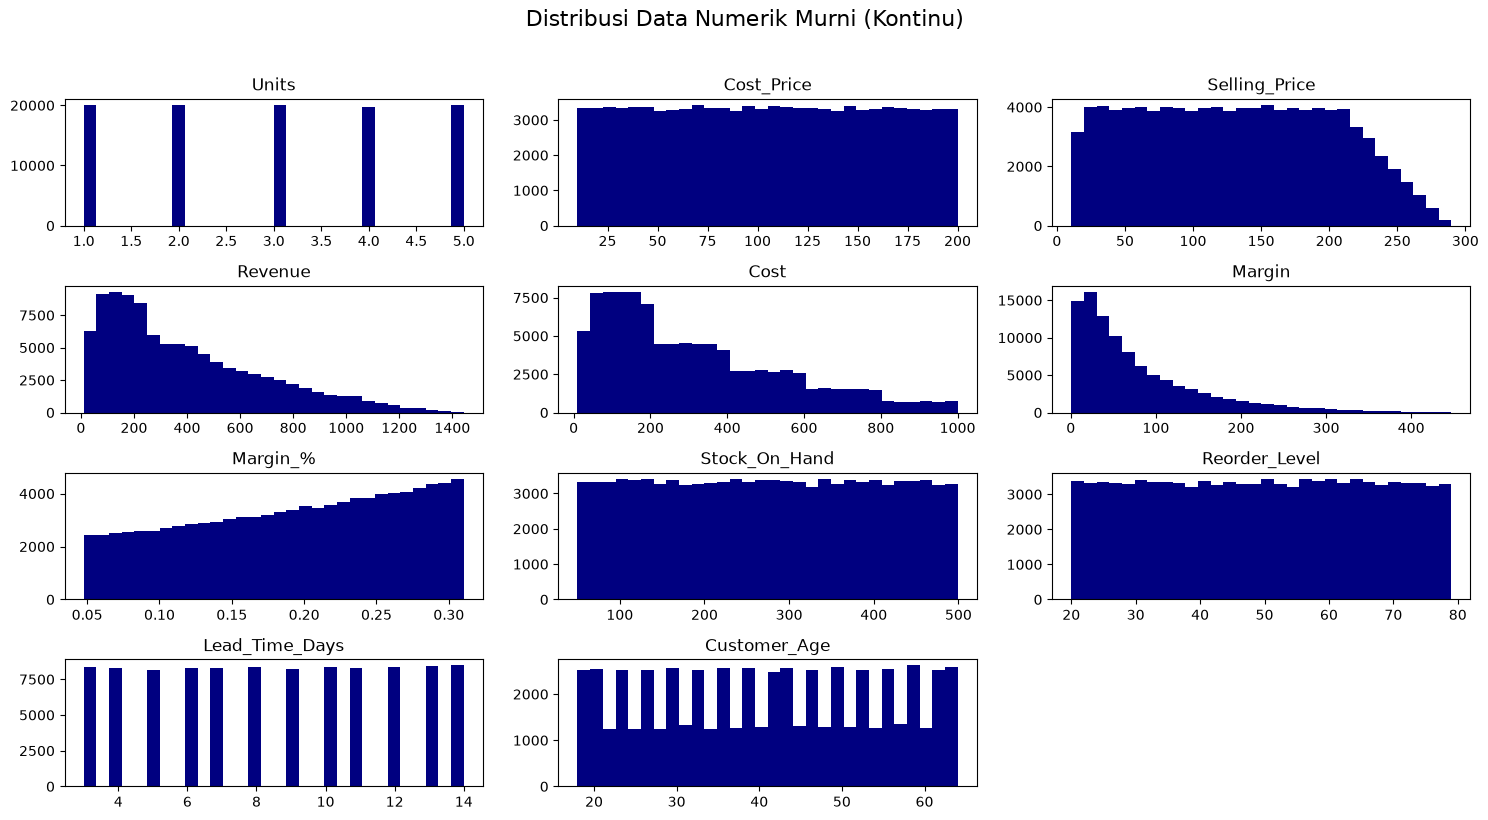

=== PROPORSI KOLOM HASIL ENCODING ===


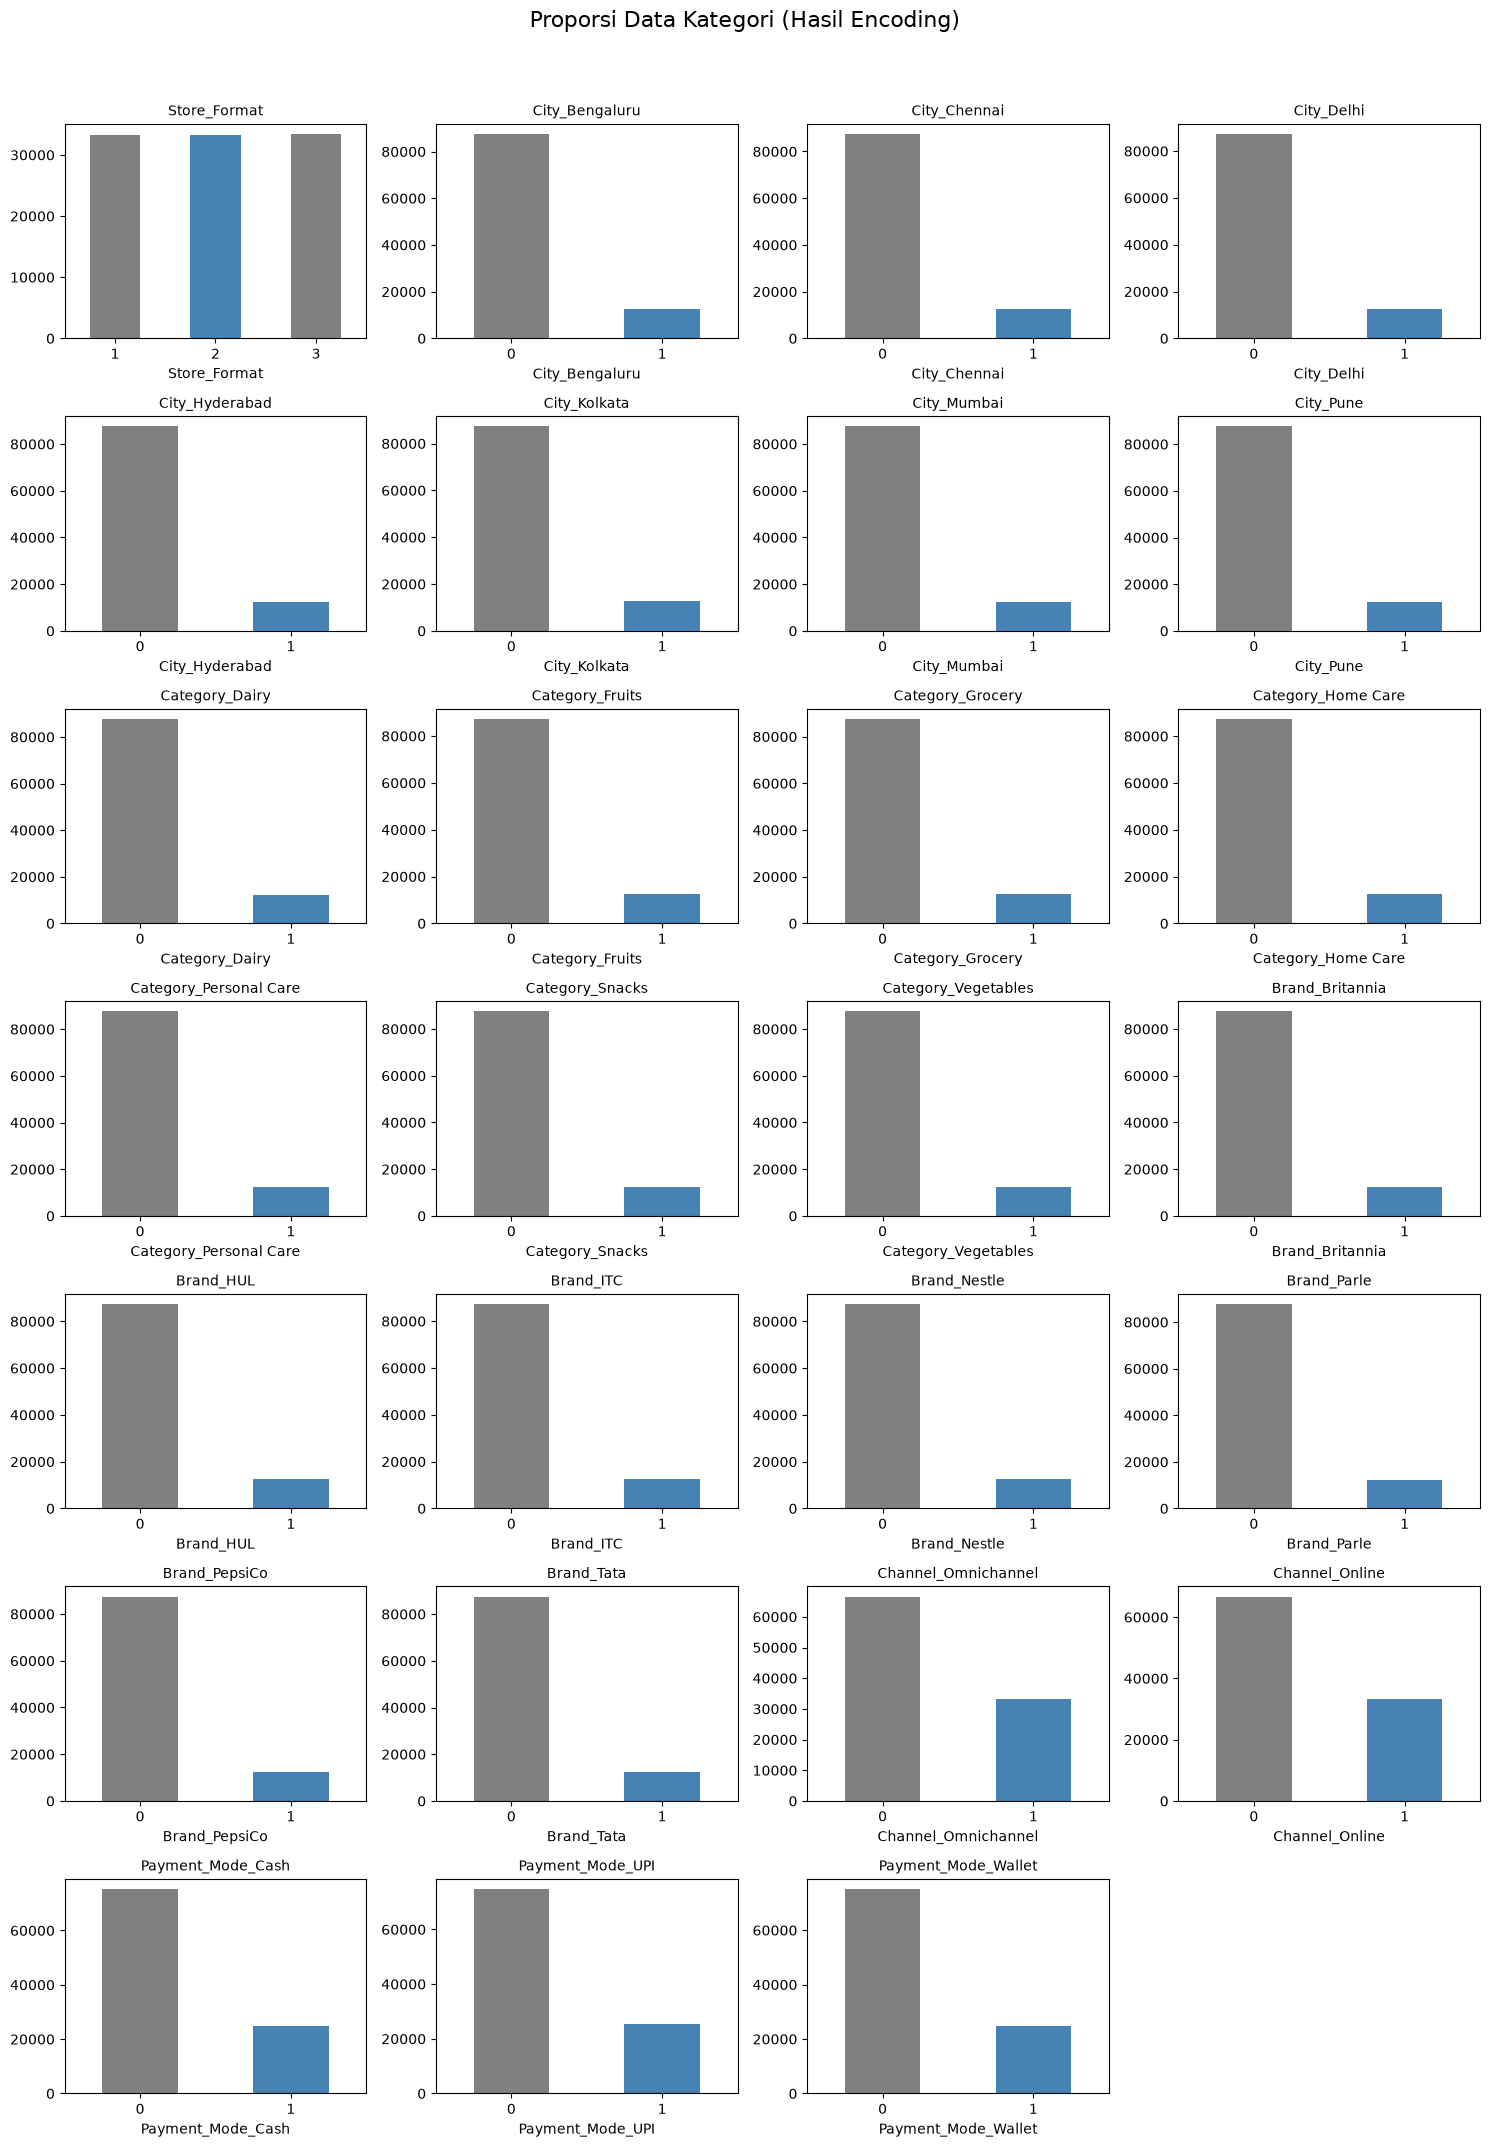


Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)



In [14]:
# 1. Ambil semua kolom numerik dan buang ID
numeric_df = df_encode.select_dtypes(include=["number"]).drop(columns=['Invoice_ID', 'Loyalty_Flag', 'Transaction_ID'], errors='ignore')

# 2. PISAHKAN KOLOM BERDASARKAN KARAKTERISTIKNYA
# Jika nilai uniknya <= 3, kemungkinan besar itu adalah hasil Encoding (Biner 0/1 atau Ordinal 1-3)
encoded_cols = [col for col in numeric_df.columns if numeric_df[col].nunique() <= 3]
# Sisanya adalah kolom numerik murni (kontinu)
continuous_cols = [col for col in numeric_df.columns if col not in encoded_cols]

# ==========================================
# VISUALISASI 1: NUMERIK MURNI (KONTINU)
# ==========================================
print("=== DISTRIBUSI KOLOM NUMERIK KONTINU ===")
numeric_df[continuous_cols].hist(color="navy", figsize=(15, 8), bins=30, grid=False)
plt.suptitle("Distribusi Data Numerik Murni (Kontinu)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ==========================================
# VISUALISASI 2: HASIL ENCODING (BINER/ORDINAL)
# ==========================================
print("=== PROPORSI KOLOM HASIL ENCODING ===")
# Menggunakan jumlah kolom untuk menentukan ukuran baris grid yang dinamis
n_cols = 4
n_rows = int(np.ceil(len(encoded_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(encoded_cols):
    # Menggunakan value_counts() dan bar plot karena datanya diskrit (0 dan 1)
    numeric_df[col].value_counts().sort_index().plot(kind='bar', ax=axes[i], color=['gray', 'steelblue'])
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', rotation=0)

# Matikan subplot sisa yang kosong
for j in range(len(encoded_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Proporsi Data Kategori (Hasil Encoding)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()
print("""
Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)
""")

<b> Hasil pengamatan </b>
<p>
   Berdasarkan visualisasi distribusi data kontinu dan proporsi data kategori yang dilampirkan, terdapat beberapa fakta data yang mendeskripsikan kondisi bisnis perusahaan. Pada grafik distribusi kontinu, metrik finansial seperti margin, pendapatan, dan biaya menunjukkan kemiringan positif yang kuat, di mana mayoritas transaksi menumpuk pada nilai nominal yang rendah. Sebaliknya, metrik pendukung operasional seperti jumlah unit per transaksi, tingkat persediaan di tangan, batas pemesanan ulang, dan waktu tunggu pengiriman terdistribusi secara seragam dan datar. Selanjutnya, pada grafik proporsi kategori hasil klasifikasi, terlihat bahwa volume transaksi terbagi rata secara presisi pada seluruh entitas, meliputi format toko, kota operasional, kategori produk, merek dagang, saluran penjualan, hingga metode pembayaran.
</p>

<h4> 9. Kesimpulan Data Exploration </h4>

<b> Hasil pengamatan </b>
<p>Berdasarkan hasil eksplorasi awal, dataset "FMCG_Retail" yang memiliki dimensi 100.000 baris dan 21 kolom memerlukan serangkaian proses pembersihan untuk mengatasi beberapa isu struktural. Pertama, ditemukan adanya inkonsistensi tipe data pada sejumlah kolom yang langsung ditindaklanjuti, yaitu pengubahan Invoice_Date dari format string menjadi datetime, Invoice_ID dari integer menjadi string, Customer_Age dari float menjadi integer, dan Loyalty_Flag menjadi tipe boolean. Selain itu, kolom-kolom kategorikal seperti City, Store_Format, Category, Brand, Channel, Payment_Mode, dan Customer_Gender juga dikonversi dari string menjadi tipe data category untuk efisiensi komputasi. Kedua, terkait penanganan missing value, nilai yang kosong pada Customer_Age diputuskan untuk dibiarkan dan akan ditangani melalui pembuatan kolom baru berisi pengelompokan umur di mana data kosong tersebut akan memiliki kelompoknya sendiri, sementara nilai kosong pada Customer_Gender langsung diisi dan dimasukkan ke dalam kategori 'O' atau others. Terakhir, untuk mengatasi masalah duplikasi pada kolom Invoice_ID, dilakukan pembuatan kolom baru yang berfungsi sebagai identifikasi unik untuk setiap baris transaksi.
     </p>

<h3>D. Data Cleaning</h3>

<h4> 1. Membuat dataframe baru yang bersih</h4>

In [15]:
# Membuat salinan dataframe agar data asli aman
df_clean = df.copy()

<h4> 2. Pengubahan Tipe Data </h4>

In [16]:
# A. Konversi Kolom Tanggal ke Datetime
df_clean['Invoice_Date'] = pd.to_datetime(df_clean['Invoice_Date'])

# B. Konversi ID ke String/Object
df_clean['Invoice_ID'] = df_clean['Invoice_ID'].astype(str)

# C. Konversi Customer_Age ke Nullable Integer ('Int64')
df_clean['Customer_Age'] = df_clean['Customer_Age'].astype('Int64')

# D. Konversi Loyalty_Flag ke Boolean (True/False)
df_clean['Loyalty_Flag'] = df_clean['Loyalty_Flag'].astype(bool)

# E. Konversi Kolom Kategorikal ke Category
kolom_kategori = [
    'City', 'Store_Format', 'Category', 'Brand', 
    'Channel', 'Payment_Mode', 'Customer_Gender'
]
for col in kolom_kategori:
    df_clean[col] = df_clean[col].astype('category')

In [17]:
# Membuat DataFrame komparasi dtypes
komparasi_dtypes = pd.DataFrame({
    'Sebelum (df)': df.dtypes,
    'Sesudah (df_clean)': df_clean.dtypes
})

# Menambahkan kolom penanda apakah tipe data berubah
komparasi_dtypes['Status Perubahan'] = komparasi_dtypes.apply(
    lambda row: 'Berubah' if str(row['Sebelum (df)']) != str(row['Sesudah (df_clean)']) else 'Tetap', 
    axis=1
)

# Tampilkan tabel komparasi
display(komparasi_dtypes)

,Sebelum (df),Sesudah (df_clean),Status Perubahan
Invoice_ID,int64,str,Berubah
Invoice_Date,str,datetime64[us],Berubah
City,str,category,Berubah
Store_Format,str,category,Berubah
Category,str,category,Berubah
Brand,str,category,Berubah
Channel,str,category,Berubah
Payment_Mode,str,category,Berubah
Units,int64,int64,Tetap
Cost_Price,float64,float64,Tetap


<b> Hasil pengamatan </b>
<p> tipe data setiap kolom sudah berhasil diubah untuk memudahkan tahap analisa 
     </p>

<h4> 3. Penanganan Missing Value</h4>

In [65]:
# 1. Penanganan Customer_Age: Membuat kolom baru pengelompokan umur (Age_Group)
df_clean['Age_Group'] = pd.cut(
    df_clean['Customer_Age'].fillna(-1),
    bins=[-2, 17, 25, 35, 50, np.inf],
    labels=['Unknown', '18-25', '26-35', '36-50', '51+']
)
# 2. Penanganan Customer_Gender: Mengisi missing value dengan kategori 'O' (Others)
if 'O' not in df_clean['Customer_Gender'].cat.categories:
    df_clean['Customer_Gender'] = df_clean['Customer_Gender'].cat.add_categories(['O'])

df_clean['Customer_Gender'] = df_clean['Customer_Gender'].fillna('O')
# Cek hasil akhirnya
print(df_clean['Age_Group'].value_counts())
print(df_clean['Customer_Gender'].value_counts())

Age_Group
Unknown    40081
36-50      19173
51+        17966
26-35      12676
18-25      10104
Name: count, dtype: int64
Customer_Gender
M    44920
F    44905
O    10175
Name: count, dtype: int64


<b> Hasil pengamatan </b>
<p> nilai kolom pada Customer_gender sudah berhasil di imputasi, dan pembuatan kolom baru untuk mengganti kolom Customer_Age juga berhasil dibuat
     </p>

<h4> 4. Penanganan Nilai Unik</h4>

In [66]:
# memastikan indeks rapi dan berurutan dari 0 sebelum dieksekusi
df_clean = df_clean.reset_index(drop=True)

df_clean['Transaction_ID'] = 'TRX-' + (df_clean.index + 1).astype(str)

# Memindahkan kolom Transaction_ID ke posisi paling depan
kolom_order = ['Transaction_ID'] + [col for col in df_clean.columns if col != 'Transaction_ID']
df_clean = df_clean[kolom_order]

# Tampilkan dataframe
display(df_clean)

,Transaction_ID,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag,Age_Group,Margin_Leakage_Flag,Basket_Size_Segment
0,TRX-1,58018430,2024-02-02 13:50:00,Kolkata,Super,Grocery,Nestle,Online,Wallet,2,148.999035,175.057209,350.114418,297.998070,52.116348,0.148855,154,31,11,20,M,True,18-25,Underperforming,Small Basket
1,TRX-2,48157952,2024-10-09 11:52:00,Hyderabad,Hyper,Home Care,PepsiCo,Offline,Wallet,1,80.626759,106.034197,106.034197,80.626759,25.407438,0.239616,130,24,5,26,F,True,26-35,Overperforming,Small Basket
2,TRX-3,23283831,2024-08-26 22:03:00,Chennai,Hyper,Snacks,PepsiCo,Online,Card,5,181.233170,208.980023,1044.900114,906.165848,138.734266,0.132773,270,44,8,27,F,False,26-35,Underperforming,Large/Max Basket
3,TRX-4,53537460,2024-06-09 04:34:00,Bengaluru,Hyper,Beverages,Nestle,Omnichannel,Card,2,195.811402,260.879960,521.759920,391.622805,130.137115,0.249420,403,63,8,<NA>,F,False,Unknown,Overperforming,Small Basket
4,TRX-5,55348596,2024-06-07 01:13:00,Delhi,Super,Snacks,ITC,Offline,Card,3,23.571888,30.624472,91.873416,70.715665,21.157751,0.230292,366,40,9,60,F,True,51+,Overperforming,Medium Basket
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,TRX-99996,51439182,2024-08-11 14:58:00,Mumbai,Express,Dairy,Britannia,Online,Cash,5,128.336814,173.727828,868.639139,641.684070,226.955069,0.261277,70,76,6,25,O,False,18-25,Overperforming,Large/Max Basket
99996,TRX-99997,76433622,2024-11-27 11:02:00,Ahmedabad,Express,Dairy,Amul,Offline,Wallet,4,183.100266,240.455066,961.820263,732.401065,229.419198,0.238526,482,31,14,25,M,True,18-25,Overperforming,Medium Basket
99997,TRX-99998,80228351,2024-02-21 09:25:00,Bengaluru,Express,Beverages,ITC,Omnichannel,Wallet,2,163.630389,174.970145,349.940290,327.260777,22.679513,0.064810,411,40,4,<NA>,F,False,Unknown,Underperforming,Small Basket
99998,TRX-99999,49574701,2024-03-30 04:11:00,Chennai,Hyper,Dairy,PepsiCo,Offline,UPI,4,50.230907,67.533143,270.132573,200.923627,69.208946,0.256204,488,46,12,21,M,True,18-25,Overperforming,Medium Basket


<b> Hasil pengamatan </b>
<p> Kolom unik berhasil dibuat untuk kebutuhan analisa
     </p>

In [20]:
print("="*60)
print("FINAL DATA QUALITY CHECK")
print("="*60)

print(f"Shape                : {df_clean.shape}")
print(f"Missing Values       : {df_clean.isna().sum().sum()}")
print(f"Duplicate Rows       : {df_clean.duplicated().sum()}")
print(f"Number of Features   : {df_clean.shape[1]}")
print(f"Number of Records    : {df_clean.shape[0]}")

FINAL DATA QUALITY CHECK
Shape                : (100000, 23)
Missing Values       : 40081
Duplicate Rows       : 0
Number of Features   : 23
Number of Records    : 100000


<h4> 5. Encoding data yang bersih</h4>

In [21]:
# Salin dari data bersih
df_encoded = df_clean.copy()

# ==========================================
# 1. PERLAKUAN UNTUK DATA ORDINAL (Ada Hierarki/Tingkatan)
# ==========================================
# Pemetaan untuk format toko (kecil ke besar)
format_mapping = {'Express': 1, 'Super': 2, 'Hyper': 3}
# Pemetaan untuk rentang usia (Unknown diberi 0 agar tidak mengganggu tren linear)
age_mapping = {'Unknown': 0, '18-25': 1, '26-35': 2, '36-50': 3, '51+': 4}

if 'Store_Format' in df_encoded.columns:
    df_encoded['Store_Format'] = df_encoded['Store_Format'].map(format_mapping).fillna(0).astype(int)

if 'Age_Group' in df_encoded.columns:
    df_encoded['Age_Group'] = df_encoded['Age_Group'].map(age_mapping).fillna(0).astype(int)

# ==========================================
# 2. PERLAKUAN UNTUK DATA NOMINAL (Tanpa Tingkatan)
# ==========================================
# Daftar kolom ragam (jenis pembayaran, saluran, dll)
kolom_nominal = ['City', 'Category', 'Brand', 'Channel', 'Payment_Mode', 'Customer_Gender']
kolom_nominal_tersedia = [col for col in kolom_nominal if col in df_encoded.columns]

# Lakukan One-Hot Encoding (menjadi biner 0 dan 1)
df_encoded = pd.get_dummies(df_encoded, columns=kolom_nominal_tersedia, drop_first=True, dtype=int)

# ==========================================
# 3. VERIFIKASI PENGECUALIAN (Pastikan ID aman)
# ==========================================
# Transaction_ID dan Invoice_ID harus tetap bertipe Object/String dan tidak berubah
print("Tipe data Transaction_ID:", df_encoded['Transaction_ID'].dtype)

# Tampilkan hasil akhir
display(df_encoded.head())
print(df_encoded.dtypes)

Tipe data Transaction_ID: str


,Transaction_ID,Invoice_ID,Invoice_Date,Store_Format,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,...,Brand_Parle,Brand_PepsiCo,Brand_Tata,Channel_Omnichannel,Channel_Online,Payment_Mode_Cash,Payment_Mode_UPI,Payment_Mode_Wallet,Customer_Gender_M,Customer_Gender_O
0,TRX-1,58018430,2024-02-02 13:50:00,2,2,148.999035,175.057209,350.114418,297.998070,52.116348,...,0,0,0,0,1,0,0,1,1,0
1,TRX-2,48157952,2024-10-09 11:52:00,3,1,80.626759,106.034197,106.034197,80.626759,25.407438,...,0,1,0,0,0,0,0,1,0,0
2,TRX-3,23283831,2024-08-26 22:03:00,3,5,181.233170,208.980023,1044.900114,906.165848,138.734266,...,0,1,0,0,1,0,0,0,0,0
3,TRX-4,53537460,2024-06-09 04:34:00,3,2,195.811402,260.879960,521.759920,391.622805,130.137115,...,0,0,0,1,0,0,0,0,0,0
4,TRX-5,55348596,2024-06-07 01:13:00,2,3,23.571888,30.624472,91.873416,70.715665,21.157751,...,0,0,0,0,0,0,0,0,0,0


Transaction_ID                       str
Invoice_ID                           str
Invoice_Date              datetime64[us]
Store_Format                       int64
Units                              int64
Cost_Price                       float64
Selling_Price                    float64
Revenue                          float64
Cost                             float64
Margin                           float64
Margin_%                         float64
Stock_On_Hand                      int64
Reorder_Level                      int64
Lead_Time_Days                     int64
Customer_Age                       Int64
Loyalty_Flag                        bool
Age_Group                          int64
City_Bengaluru                     int64
City_Chennai                       int64
City_Delhi                         int64
City_Hyderabad                     int64
City_Kolkata                       int64
City_Mumbai                        int64
City_Pune                          int64
Category_Dairy  

In [67]:
df_clean[df_clean.duplicated(subset=['Invoice_ID'], keep=False)].sort_values(by='Invoice_ID')

,Transaction_ID,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag,Age_Group,Margin_Leakage_Flag,Basket_Size_Segment
7231,TRX-7232,10626453,2024-05-08 17:34:00,Ahmedabad,Super,Dairy,Nestle,Omnichannel,Wallet,3,127.292978,164.444498,493.333495,381.878934,111.454561,0.225921,289,63,6,30,F,True,26-35,Overperforming,Medium Basket
44817,TRX-44818,10626453,2024-05-24 08:36:00,Hyderabad,Super,Personal Care,Parle,Omnichannel,Card,1,194.537132,210.061916,210.061916,194.537132,15.524784,0.073906,274,24,7,<NA>,F,False,Unknown,Underperforming,Small Basket
33690,TRX-33691,11762171,2024-02-28 11:12:00,Bengaluru,Super,Beverages,Tata,Omnichannel,Card,3,96.824572,112.605082,337.815246,290.473715,47.341530,0.140140,115,54,3,<NA>,F,False,Unknown,Underperforming,Medium Basket
97489,TRX-97490,11762171,2024-07-03 10:49:00,Bengaluru,Super,Vegetables,HUL,Offline,Card,1,145.610215,185.530928,185.530928,145.610215,39.920714,0.215170,324,50,10,53,F,False,51+,Overperforming,Small Basket
49989,TRX-49990,14111027,2024-12-27 05:33:00,Bengaluru,Express,Personal Care,Parle,Omnichannel,UPI,2,83.063733,119.790795,239.581590,166.127466,73.454124,0.306593,125,48,13,<NA>,F,True,Unknown,Overperforming,Small Basket
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94621,TRX-94622,96302106,2024-04-23 15:28:00,Bengaluru,Hyper,Home Care,Britannia,Offline,Card,1,104.651997,141.182147,141.182147,104.651997,36.530151,0.258745,335,60,4,47,M,True,36-50,Overperforming,Small Basket
12700,TRX-12701,97463404,2024-02-07 08:53:00,Chennai,Hyper,Home Care,Nestle,Offline,Cash,1,28.117904,39.038553,39.038553,28.117904,10.920648,0.279740,182,21,11,51,O,False,51+,Overperforming,Small Basket
52927,TRX-52928,97463404,2024-05-26 14:43:00,Ahmedabad,Super,Snacks,ITC,Online,Cash,1,139.660058,187.400226,187.400226,139.660058,47.740168,0.254750,165,63,3,33,M,False,26-35,Overperforming,Small Basket
42938,TRX-42939,97795248,2024-12-01 08:39:00,Mumbai,Express,Home Care,PepsiCo,Online,Card,1,126.067663,136.859333,136.859333,126.067663,10.791670,0.078852,167,40,11,31,F,False,26-35,Underperforming,Small Basket


<h4> 6. Cek Outlier Numerikal</h4>

In [22]:
# 1. OTOMATISASI: Mengambil kolom numerik langsung dari df_clean (Sangat Aman)
all_numeric_cols = df_clean.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()

# 2. PENGECUALIAN: Hanya membuang ID dan Flag
kolom_dikecualikan = ['Transaction_ID', 'Invoice_ID', 'Loyalty_Flag']
kolom_kontinu = [col for col in all_numeric_cols if col not in kolom_dikecualikan]

# ============================================
# SUMMARY OUTLIER CHECK (IQR) PADA METRIK BISNIS (DF_CLEAN)
# ============================================
outlier_data = []

for col in kolom_kontinu:
    data_col = df_clean[col].dropna()
    
    q1 = data_col.quantile(0.25)
    q3 = data_col.quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    n_outliers = ((data_col < lower) | (data_col > upper)).sum()
    pct_outliers = (n_outliers / len(data_col)) * 100
    
    outlier_data.append({
        'Kolom': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Jumlah Outlier': n_outliers,
        'Persentase (%)': round(pct_outliers, 2)
    })

# Tampilkan dalam bentuk dataframe yang terurut dari outlier terbanyak
df_outlier_summary = pd.DataFrame(outlier_data).sort_values(by='Jumlah Outlier', ascending=False).reset_index(drop=True)
display(df_outlier_summary)

,Kolom,Q1,Q3,IQR,Jumlah Outlier,Persentase (%)
0,Margin,24.45,110.08,85.63,4946,4.95
1,Revenue,155.42,573.06,417.65,1191,1.19
2,Cost,125.47,462.38,336.91,717,0.72
3,Selling_Price,71.33,188.85,117.53,0,0.00
4,Cost_Price,57.48,152.32,94.84,0,0.00
5,Units,2.00,4.00,2.00,0,0.00
6,Margin_%,0.13,0.26,0.13,0,0.00
7,Stock_On_Hand,161.00,387.00,226.00,0,0.00
8,Reorder_Level,34.00,64.00,30.00,0,0.00
9,Lead_Time_Days,6.00,12.00,6.00,0,0.00


<b> Hasil pengamatan </b>
<p> Terdeteksi Outlier pada kolom Margin(4.95%), Revenue(1.19%), dan Cost(0.72%). Outlier ini akan dipertahankan karena merupakan outlier alami transaksi (natural business outliers) karena berasal dari hasil perkalian volume dan harga jual, bukan kesalahan input data.
     </p>

<h4> 7. Cek Outlier Kategorikal</h4>

In [23]:
# 1. OTOMATISASI: Ambil kolom kategorikal/teks murni dari df_clean
kolom_kategorikal = df_clean.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# 2. PENGECUALIAN: Buang ID karena setiap baris pasti unik (proporsi mendekati 0%)
kolom_dikecualikan = ['Transaction_ID', 'Invoice_ID']
kolom_kategorikal = [col for col in kolom_kategorikal if col not in kolom_dikecualikan]

# ============================================
# SUMMARY PROPORSI KATEGORIKAL (MENDETEKSI MINORITAS)
# ============================================
proporsi_data = []

# Tentukan batas persentase untuk dianggap sebagai "Outlier/Minoritas" (misal: 5%)
batas_minoritas = 5.0 

for col in kolom_kategorikal:
    # Menghitung jumlah frekuensi dan persentase untuk setiap nilai di dalam kolom
    counts = df_clean[col].value_counts(dropna=False)
    pcts = df_clean[col].value_counts(normalize=True, dropna=False) * 100
    
    for kategori_item, count_val in counts.items():
        pct_val = pcts[kategori_item]
        
        # Memberikan label apakah kategori tersebut normal atau minoritas
        status = "Minoritas" if pct_val < batas_minoritas else "Normal"
        
        proporsi_data.append({
            'Nama Kolom': col,
            'Nilai Kategori': kategori_item,
            'Frekuensi': count_val,
            'Proporsi (%)': round(pct_val, 2),
            'Status': status
        })

# 3. OUTPUT TABEL: Tampilkan dalam bentuk dataframe yang rapi
df_proporsi_kategori = pd.DataFrame(proporsi_data)

# Urutkan berdasarkan kolom dan proporsi terkecil
df_proporsi_kategori = df_proporsi_kategori.sort_values(by=['Nama Kolom', 'Proporsi (%)']).reset_index(drop=True)
display(df_proporsi_kategori)

# (Opsional) Filter hanya yang berstatus Minoritas untuk melihat daftar "Outlier"
# display(df_proporsi_kategori[df_proporsi_kategori['Status'] == 'Minoritas/Rare'])

,Nama Kolom,Nilai Kategori,Frekuensi,Proporsi (%),Status
0,Age_Group,18-25,10104,10.10,Normal
1,Age_Group,26-35,12676,12.68,Normal
2,Age_Group,51+,17966,17.97,Normal
3,Age_Group,36-50,19173,19.17,Normal
4,Age_Group,Unknown,40081,40.08,Normal
5,Brand,Parle,12233,12.23,Normal
6,Brand,Tata,12461,12.46,Normal
7,Brand,Britannia,12497,12.50,Normal
8,Brand,PepsiCo,12507,12.51,Normal
9,Brand,Amul,12521,12.52,Normal


<b>Hasil Pengamatan</b>

<p>Seluruh kategori memiliki status "Normal" dan tidak ada satu pun yang berstatus "Minoritas". Format toko terbagi sempurna di angka ~33%, saluran penjualan di ~33%, kota di ~12%, dan metode pembayaran di ~24%. Secara data, isolasi ini menyimpulkan bahwa Anda tidak perlu menghapus atau menggabungkan kategori apa pun. Semua entitas sangat seimbang dan valid untuk diadu kinerjanya di tahap multivariat.</p>

<h4>8. Feature Engineering</h4>

In [69]:
df_clean['Margin_Leakage_Flag'] = np.where(
    df_clean['Margin_%'] < 0.1933, 
    'Underperforming', 
    'Overperforming'
)
df_clean['Margin_Leakage_Flag'] = df_clean['Margin_Leakage_Flag'].astype('category')
display(df_clean[['Margin', 'Revenue', 'Cost', 'Margin_%', 'Margin_Leakage_Flag',]].head(10))

,Margin,Revenue,Cost,Margin_%,Margin_Leakage_Flag
0,52.116348,350.114418,297.998070,0.148855,Underperforming
1,25.407438,106.034197,80.626759,0.239616,Overperforming
2,138.734266,1044.900114,906.165848,0.132773,Underperforming
3,130.137115,521.759920,391.622805,0.249420,Overperforming
4,21.157751,91.873416,70.715665,0.230292,Overperforming
5,3.847523,54.244938,50.397415,0.070929,Underperforming
6,1.504347,13.728704,12.224357,0.109577,Underperforming
7,11.490639,95.104355,83.613716,0.120821,Underperforming
8,31.879847,253.760721,221.880874,0.125630,Underperforming
9,80.773234,486.438440,405.665206,0.166050,Underperforming


<h3>E. EDA (Exploratory Data Analysis)</h3>

<h4> 1. Univariate Analysis</h4>

<h5> 1.1 Distribusi Variabel Numerik</h5>

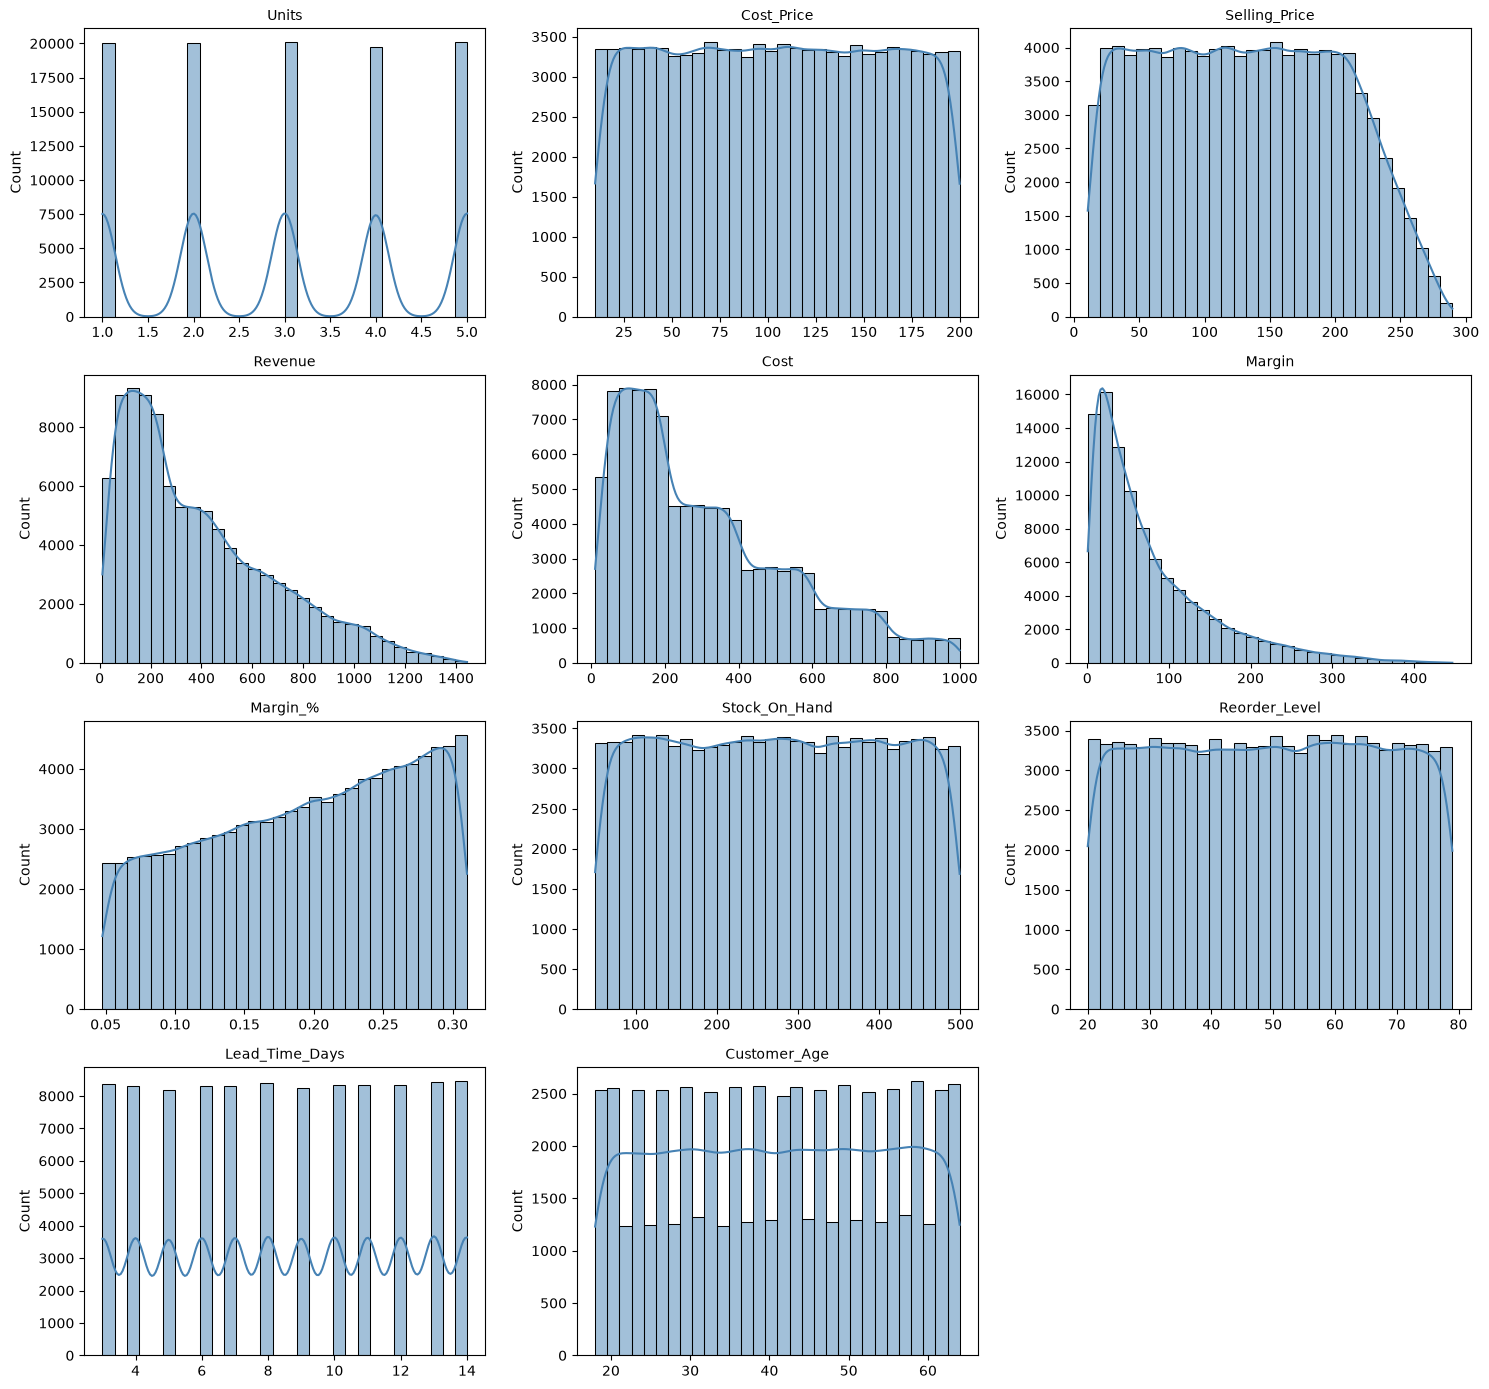

UJI NORMALITAS (df_clean) - Kolmogorov-Smirnov Test


,kolom,ks_statistic,p_value,skewness,kurtosis,distribusi_normal
0,Units,0.1605,0.000000e+00,0.004,-1.299,Tidak
1,Cost_Price,0.0574,2.788509e-287,0.002,-1.198,Tidak
2,Selling_Price,0.0556,5.800008e-269,0.092,-1.073,Tidak
3,Revenue,0.1118,0.000000e+00,0.939,0.162,Tidak
4,Cost,0.1154,0.000000e+00,0.881,-0.047,Tidak
5,Margin,0.1473,0.000000e+00,1.568,2.416,Tidak
6,Margin_%,0.0691,0.000000e+00,-0.230,-1.129,Tidak
7,Stock_On_Hand,0.0597,5.355993e-310,0.002,-1.201,Tidak
8,Reorder_Level,0.0663,0.000000e+00,-0.004,-1.200,Tidak
9,Lead_Time_Days,0.0991,0.000000e+00,-0.006,-1.218,Tidak



Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)



In [16]:
# ============================================
# 0. OTOMATISASI DETEKSI KOLOM NUMERIK (df_clean)
# ============================================
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64', 'int32', 'Int64']).columns.tolist()

# Pengecualian kolom ID / Flag yang tidak relevan diuji distribusinya
kolom_dikecualikan = ['Transaction_ID', 'Invoice_ID', 'Loyalty_Flag']
numeric_cols_to_check = [col for col in numeric_cols if col not in kolom_dikecualikan]

# ============================================
# 1. SUBPLOT DISTRIBUSI (HISTOGRAM) SEMUA KOLOM SEKALIGUS
# ============================================
n_cols = 3
n_rows = -(-len(numeric_cols_to_check) // n_cols)  # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_to_check):
    data_plot = df_clean[col].dropna()
    sns.histplot(data_plot, kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')

# Matikan subplot kosong jika jumlah kolom tidak pas dengan grid
for j in range(len(numeric_cols_to_check), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('distribusi_semua_kolom_fmcg.png', dpi=100, bbox_inches='tight')
plt.show()

# ============================================
# 2. UJI NORMALITAS - KOLMOGOROV-SMIRNOV (df_clean)
# ============================================
print("="*80)
print("UJI NORMALITAS (df_clean) - Kolmogorov-Smirnov Test")
print("="*80)

results = []
for col in numeric_cols_to_check:
    data = df_clean[col].dropna()
    
    # Standardisasi dulu (z-score) karena K-S butuh dibandingkan ke distribusi normal standar
    data_standardized = (data - data.mean()) / data.std()
    ks_stat, p_value = stats.kstest(data_standardized, 'norm')
    skewness = stats.skew(data)
    kurtosis = stats.kurtosis(data)  # excess kurtosis (0 = normal)

    results.append({
        'kolom': col,
        'ks_statistic': round(ks_stat, 4),
        'p_value': p_value,
        'skewness': round(skewness, 3),
        'kurtosis': round(kurtosis, 3),
        'distribusi_normal': 'Tidak' if p_value < 0.05 else 'Ya'
    })

df_normality = pd.DataFrame(results)
display(df_normality)

print("""
Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)
""")

<h5> 1.2 Distribusi Variabel Kategorikal</h5>

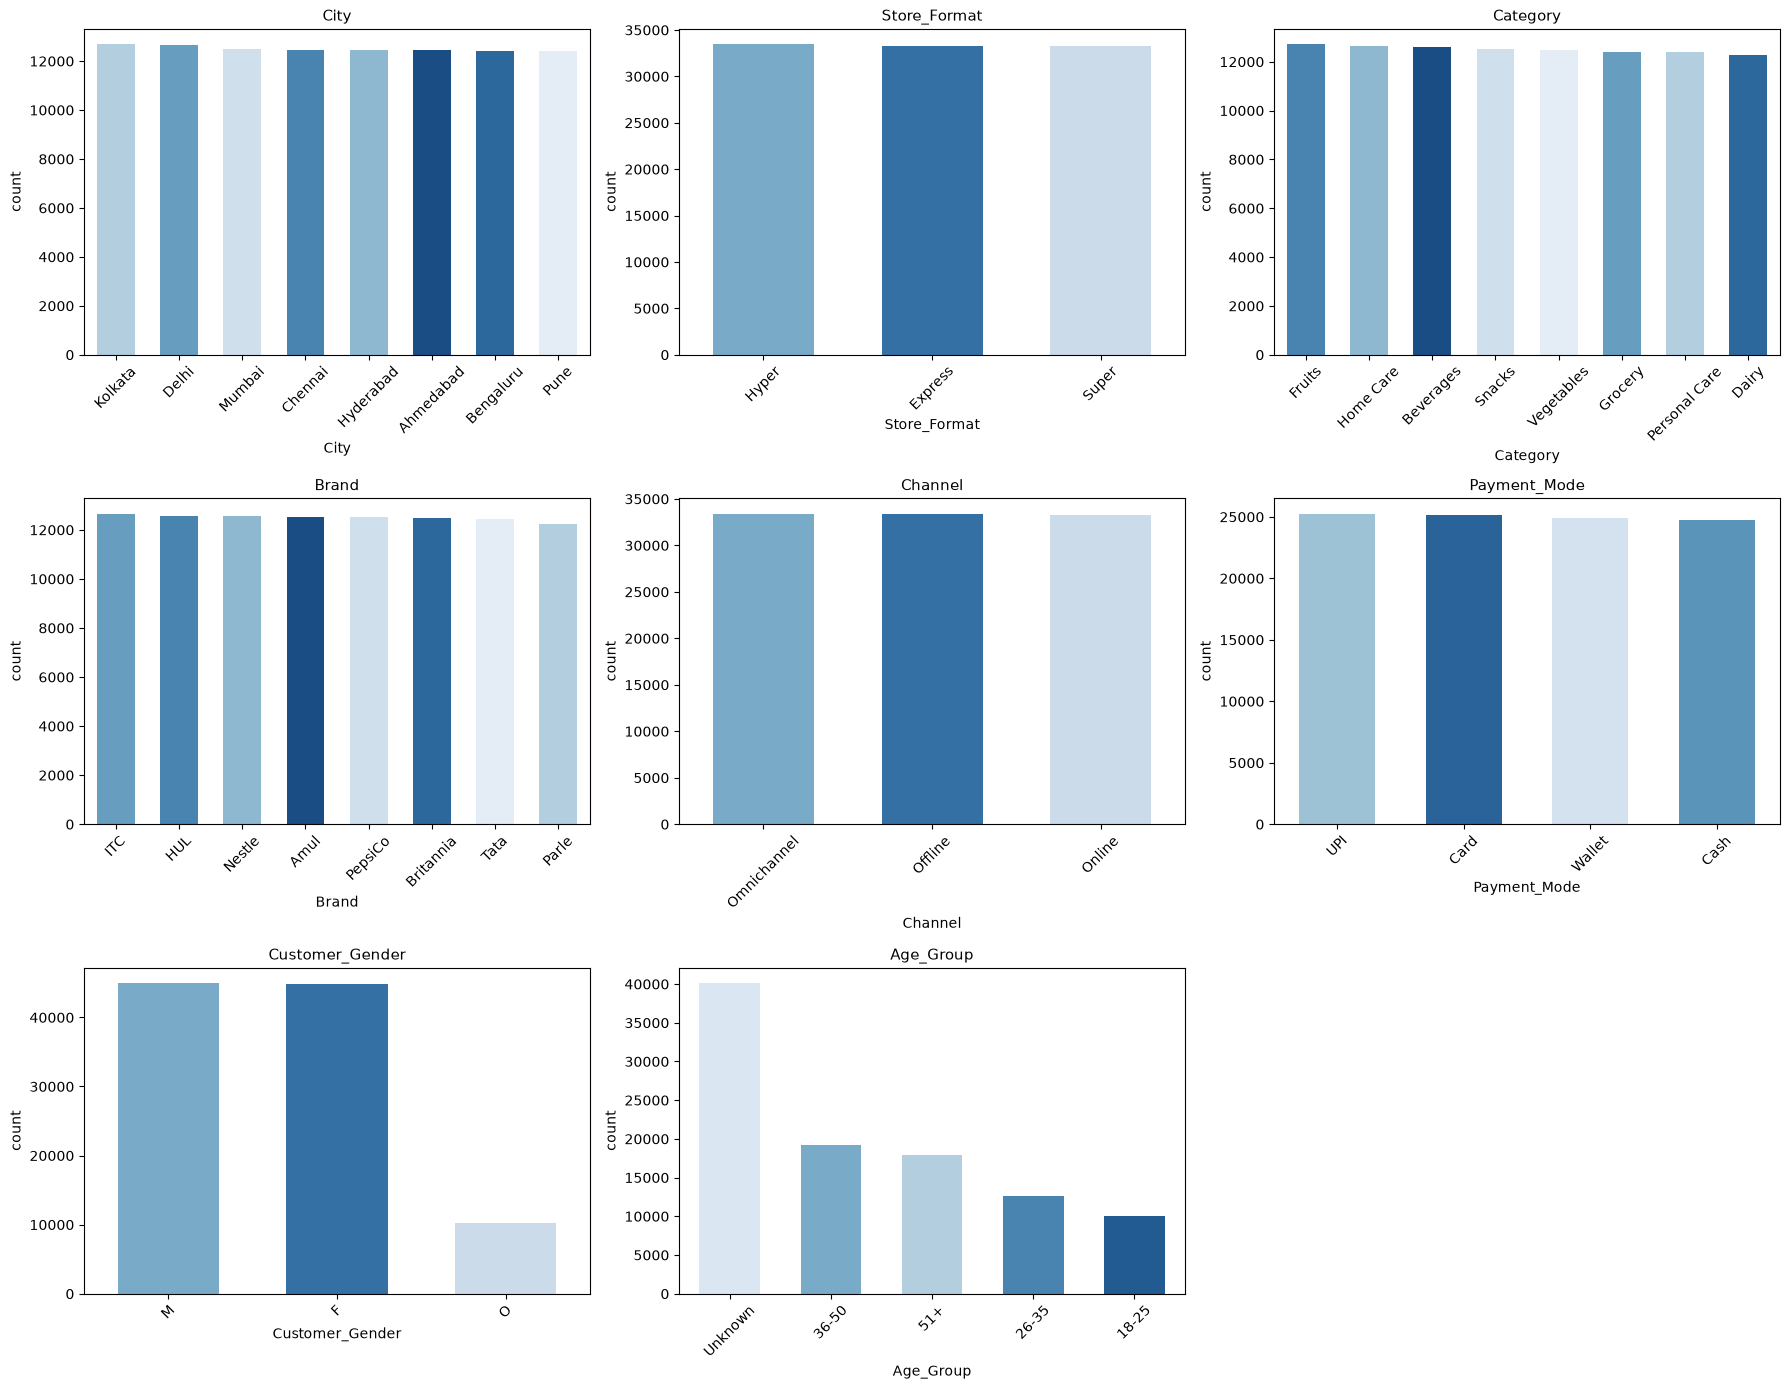

In [13]:
categorical_cols = [
    'City', 'Store_Format', 'Category', 'Brand',
    'Channel', 'Payment_Mode', 'Customer_Gender', 'Age_Group'
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df_clean[col].value_counts().index if not (df_clean[col].dtype.name == 'category' and df_clean[col].cat.ordered) else None
    sns.countplot(
        data=df_clean, 
        x=col, 
        ax=axes[i], 
        order=order, 
        hue=col, 
        dodge=False,       # <--- WAJIB ADA agar slot sumbu X tidak terpisah-pisah
        width=0.6,         # <--- Mengatur ketebalan batang
        palette='Blues_r', 
        legend=False
    )
    
    axes[i].set_title(col, fontsize=11)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [14]:
# ==========================================================
# DISTRIBUSI VARIABEL KATEGORIKAL
# ==========================================================

for col in categorical_cols:
    print("="*80)
    print(f"DISTRIBUSI : {col.upper()}")
    print("="*80)

    freq = df_clean[col].value_counts()
    percent = df_clean[col].value_counts(normalize=True) * 100

    summary = pd.DataFrame({
        "Count": freq,
        "Percentage (%)": percent.round(2)
    })

    display(summary)

DISTRIBUSI : CITY


,Count,Percentage (%)
City,,
Kolkata,12681,12.68
Delhi,12649,12.65
Mumbai,12492,12.49
Chennai,12467,12.47
Hyderabad,12440,12.44
Ahmedabad,12436,12.44
Bengaluru,12432,12.43
Pune,12403,12.40


DISTRIBUSI : STORE_FORMAT


,Count,Percentage (%)
Store_Format,,
Hyper,33443,33.44
Express,33314,33.31
Super,33243,33.24


DISTRIBUSI : CATEGORY


,Count,Percentage (%)
Category,,
Fruits,12708,12.71
Home Care,12630,12.63
Beverages,12585,12.58
Snacks,12514,12.51
Vegetables,12472,12.47
Grocery,12412,12.41
Personal Care,12409,12.41
Dairy,12270,12.27


... (6 outputs left out)

DISTRIBUSI : CUSTOMER_GENDER


,Count,Percentage (%)
Customer_Gender,,
M,44920,44.92
F,44905,44.90
O,10175,10.17


DISTRIBUSI : AGE_GROUP


,Count,Percentage (%)
Age_Group,,
Unknown,40081,40.08
36-50,19173,19.17
51+,17966,17.97
26-35,12676,12.68
18-25,10104,10.10


In [15]:
# Tentukan daftar kolom yang mau dicek
kolom_pilihan = ['Revenue', 'Margin', 'Stock_On_Hand', 'Reorder_Level']

# Tampilkan info untuk kolom pilihan saja
df_clean[kolom_pilihan].describe().round(2)

,Revenue,Margin,Stock_On_Hand,Reorder_Level
count,100000.00,100000.00,100000.00,100000.00
mean,393.35,78.74,274.16,49.47
std,297.15,74.24,129.85,17.31
min,10.65,0.56,50.00,20.00
25%,155.42,24.45,161.00,34.00
50%,313.35,53.55,274.00,50.00
75%,573.06,110.08,387.00,64.00
max,1443.13,447.21,499.00,79.00


<b>Hasil Pengamatan</b>


Finansial (Revenue & Margin)
1. Finansial (Revenue & Margin)
    Fakta Data:

        Distribusi Revenue dan Margin berdistribusi right-skewed (miring ke kanan).

        Rata-rata Revenue sebesar ₹393,35, sedangkan nilai tengahnya (median) berada di ₹313,35 dengan nilai puncak transaksi hingga ₹1.443,13.

        Transaksi bernilai tinggi (25% transaksi teratas di atas nilai Q3 ₹573,06) menyumbang 52,47% dari total pendapatan bisnis.

        Rata-rata Margin tercatat sebesar ₹78,74 (median ₹53,55) dengan tingkat marjin bersih rata-rata 19,3%.

    Rekomendasi:

        Disarankan untuk memfokuskan strategi retensi pada segmen transaksi bernilai tinggi (high-value transactions) di ekor kanan grafik distribusi, karena segmen 25% ini menopang lebih dari separuh pendapatan perusahaan.

        Disarankan agar analisis tingkat margin tidak menggunakan ukuran rata-rata (mean) akibat adanya pencilan bernilai tinggi, melainkan menggunakan median sebagai tolok ukur baseline kinerja keuangan.

2. Operasional Persediaan (Stock_On_Hand vs Reorder_Level)

    Fakta Data:

        Nilai persediaan fisik (Stock_On_Hand) memiliki batas minimum 50 unit dan menyebar seragam hingga 499 unit.

        Batas pengadaan ulang (Reorder_Level) memiliki rentang maksimum hingga 79 unit.

        Terdapat 1.624 transaksi (1,62%) di mana nilai persediaan berada di bawah titik pengadaan ulang (Stock_On_Hand < Reorder_Level).

    Rekomendasi:

        Disarankan agar tim manajemen logistik segera melakukan evaluasi terhadap skema pengalokasian stok persediaan, karena keberadaan 1.624 insiden persediaan kritis berpotensi menyebabkan kelangkaan barang di rak (out-of-stock).

        Disarankan untuk membangun sistem otomatisasi peringatan dini (early warning system) yang menghitung titik pemesanan kembali berbasis perkiraan permintaan agar transaksi bernilai tinggi tidak terganggu oleh kekosongan barang.

3. Profil Demografi Pelanggan (Age_Group)

    Fakta Data:

        Kolom pengelompokan usia (Age_Group) didominasi oleh kategori Unknown sebanyak 40.081 transaksi (40,08%).

        Untuk data usia teridentifikasi, kelompok usia produktif 36–50 tahun (19,17%) dan 51+ tahun (17,96%) mencetak jumlah transaksi terbesar.

    Rekomendasi:

        Disarankan kepada tim data engineering dan marketing untuk meningkatkan kualitas pencatatan data identitas pelanggan (data collection hygiene) pada kasir offline maupun platform digital guna meminimalkan porsi data anonim.

        Disarankan agar segmentasi pelanggan untuk analisis bisnis utama tidak bertumpu pada demografi usia murni, melainkan dialihkan ke segmentasi berbasis perilaku belanja (behavioral/channel segmentation) seperti keanggotaan loyalitas dan saluran pembelian.

<h5> 1.3 Penambahan Kolom untuk cek stock</h5>

In [16]:
df_clean['is_critical_stock'] = df_clean['Stock_On_Hand'] < df_clean['Reorder_Level']

In [17]:
df_clean[df_clean['is_critical_stock']]

,Transaction_ID,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,...,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag,Age_Group,is_critical_stock
149,150,62516571,2024-01-22 06:43:00,Chennai,Express,Beverages,ITC,Online,Wallet,4,...,56.426965,0.130898,69,73,13,<NA>,M,True,Unknown,True
253,254,41497182,2024-04-30 09:35:00,Chennai,Hyper,Home Care,HUL,Online,Cash,1,...,34.855967,0.189485,50,79,6,64,F,False,51+,True
308,309,22600290,2024-04-25 05:28:00,Chennai,Hyper,Personal Care,Britannia,Omnichannel,Card,1,...,37.785495,0.236688,51,69,6,28,F,False,26-35,True
394,395,87487063,2024-09-19 18:34:00,Kolkata,Super,Grocery,Britannia,Omnichannel,Cash,2,...,56.813201,0.165263,69,72,11,<NA>,M,True,Unknown,True
547,548,67091344,2024-08-03 18:25:00,Hyderabad,Express,Personal Care,ITC,Omnichannel,Wallet,2,...,42.185376,0.123324,53,72,10,39,M,False,36-50,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99819,99820,88724048,2024-07-11 09:09:00,Pune,Hyper,Snacks,PepsiCo,Offline,Card,5,...,24.173507,0.155901,75,79,9,<NA>,F,False,Unknown,True
99872,99873,96166518,2024-06-24 02:12:00,Chennai,Express,Vegetables,ITC,Omnichannel,UPI,5,...,157.758457,0.187088,77,78,14,<NA>,F,False,Unknown,True
99936,99937,39822563,2024-01-10 10:03:00,Mumbai,Super,Dairy,Parle,Online,UPI,1,...,6.136297,0.116593,52,62,12,23,O,False,18-25,True
99983,99984,14990572,2024-06-18 08:00:00,Kolkata,Express,Dairy,Amul,Online,Cash,5,...,148.564396,0.308204,59,71,4,35,M,True,26-35,True


<h4> 2. Bivariate Analysis</h4>

<h5> 2.1 Perbandingan Revenue dan Margin antar Channel Penjualan serta Status Pelanggan</h5>

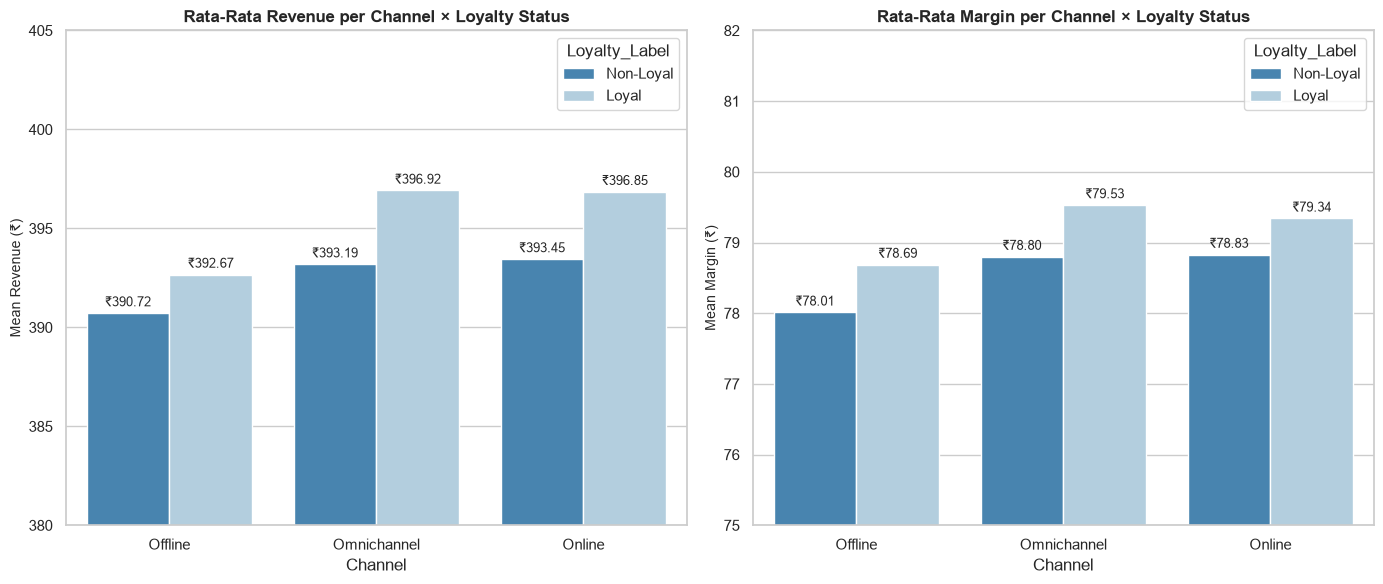

In [18]:
# 1. Menghitung rata-rata Revenue dan Margin per Channel x Loyalty_Flag
df_grouped = df_clean.groupby(['Channel', 'Loyalty_Flag'])[['Revenue', 'Margin']].mean().reset_index()
df_grouped['Loyalty_Label'] = df_grouped['Loyalty_Flag'].map({True: 'Loyal', False: 'Non-Loyal'})

# 2. Membuat Layout Subplot 1x2 (Berdampingan)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ==============================================================================
# GRAFIK 1: Rata-Rata Revenue
# ==============================================================================
sns.barplot(
    data=df_grouped, x='Channel', y='Revenue', hue='Loyalty_Label',
    palette='Blues_r', ax=axes[0]
)
axes[0].set_title('Rata-Rata Revenue per Channel × Loyalty Status', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Revenue (₹)', fontsize=10)
axes[0].set_ylim(380, 405)  # Zoom-in skala sumbu Y agar selisih angka terlihat jelas

# Menambahkan anotasi nilai angka di atas batang
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'₹{h:.2f}',
                         (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                         textcoords='offset points')

# ==============================================================================
# GRAFIK 2: Rata-Rata Margin
# ==============================================================================
sns.barplot(
    data=df_grouped, x='Channel', y='Margin', hue='Loyalty_Label',
    palette='Blues_r', ax=axes[1]
)
axes[1].set_title('Rata-Rata Margin per Channel × Loyalty Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean Margin (₹)', fontsize=10)
axes[1].set_ylim(75, 82)  # Zoom-in skala sumbu Y

# Menambahkan anotasi nilai angka di atas batang
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'₹{h:.2f}',
                         (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                         textcoords='offset points')

plt.tight_layout()
plt.show()

<b>Hasil Pengamatan</b>
                       
Fakta Data

    Dominasi Pelanggan Loyal: Pelanggan dengan status keanggotaan loyal (Loyal) secara konsisten menghasilkan rata-rata Revenue dan Margin lebih tinggi dibandingkan pelanggan biasa (Non-Loyal) di seluruh saluran penjualan (Channel).

    Saluran Berkinerja Tertinggi (Omnichannel & Online):

        Pelanggan loyal di saluran Omnichannel mencatatkan nilai transaksi rata-rata terbesar dengan Revenue ₹396,92 dan Margin ₹79,53.

        Pelanggan loyal di saluran Online menyusul sangat dekat dengan Revenue ₹396,85 dan Margin ₹79,34.

    Ketertinggalan Saluran Offline: Saluran Offline menghasilkan rata-rata Revenue dan Margin paling rendah, baik untuk kelompok Non-Loyal (₹390,72 / ₹78,01) maupun kelompok Loyal (₹392,67 / ₹78,69).

Rekomendasi

    Dorong Strategi Migrasi Pelanggan ke Saluran Digital/Omnichannel: Disarankan agar tim pemasaran merancang program insentif (seperti voucher eksklusif aplikasi atau poin loyalitas ganda) untuk mendorong pelanggan Offline mendaftar keanggotaan dan bertransaksi secara Omnichannel, guna meningkatkan ukuran keranjang belanja (basket size).

    Fokus Retensi Pelanggan Digital Loyal: Disarankan untuk memprioritaskan alokasi anggaran retensi dan pengalaman pengguna (user experience) pada platform Online dan Omnichannel, mengingat segmen pelanggan loyal di kedua saluran ini memberikan kontribusi profitabilitas marjinal paling tinggi.

Tabel Agregasi Margin berdasarkan Channel:
    Channel  Rata-rata Margin  Median Margin
    Offline         78.212327      53.381198
Omnichannel         79.018100      54.233812
     Online         78.980748      53.084999
--------------------------------------------------


C:\Users\User\AppData\Local\Temp\ipykernel_8852\1177629687.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\User\AppData\Local\Temp\ipykernel_8852\1177629687.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


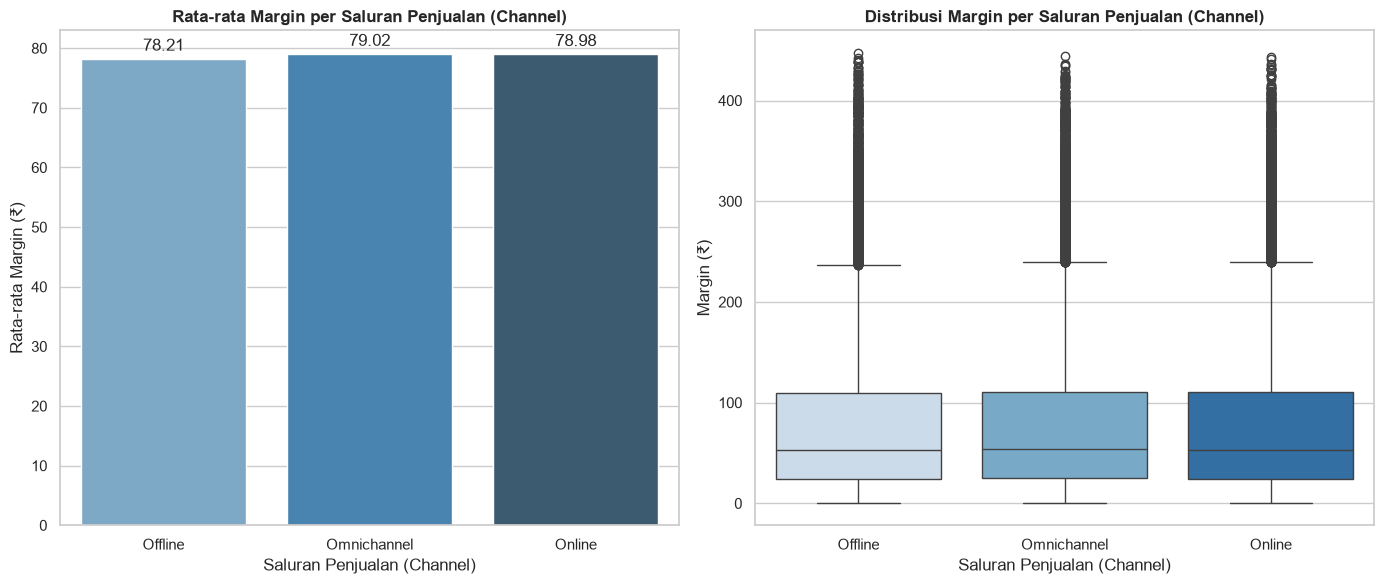

In [19]:
# Asumsi nama dataframe Anda adalah df_clean
# Variabel 1: Channel (Kategorikal)
# Variabel 2: Margin (Numerik)

# 1. Agregasi Data (Menghitung Rata-rata dan Median Margin per Channel)
bivariate_1_agg = df_clean.groupby('Channel')['Margin'].agg(['mean', 'median']).reset_index()
bivariate_1_agg.rename(columns={'mean': 'Rata-rata Margin', 'median': 'Median Margin'}, inplace=True)

# Menampilkan tabel hasil agregasi
print("Tabel Agregasi Margin berdasarkan Channel:")
print(bivariate_1_agg.to_string(index=False))
print("-" * 50)

# 2. Visualisasi Data (Bar Plot & Box Plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Plot Kiri: Bar Plot untuk Rata-rata Margin per Channel
sns.barplot(
    data=bivariate_1_agg, 
    x='Channel', 
    y='Rata-rata Margin', 
    palette='Blues_d', 
    ax=axes[0]
)
axes[0].set_title('Rata-rata Margin per Saluran Penjualan (Channel)', fontweight='bold')
axes[0].set_xlabel('Saluran Penjualan (Channel)')
axes[0].set_ylabel('Rata-rata Margin (₹)')

# Menambahkan label angka di atas bar
for p in axes[0].patches:
    axes[0].annotate(format(p.get_height(), '.2f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

# Plot Kanan: Box Plot untuk melihat sebaran dan pencilan (outlier) per Channel
sns.boxplot(
    data=df_clean, 
    x='Channel', 
    y='Margin', 
    palette='Blues', 
    ax=axes[1]
)
axes[1].set_title('Distribusi Margin per Saluran Penjualan (Channel)', fontweight='bold')
axes[1].set_xlabel('Saluran Penjualan (Channel)')
axes[1].set_ylabel('Margin (₹)')

plt.tight_layout()
plt.show()

<b>Hasil Pengamatan</b>

Fakta Data

    Konsentrasi Risiko pada Barang Berperputaran Cepat (Fast-Moving Goods): Kasus insiden persediaan kritis (Stock_On_Hand < Reorder_Level) paling banyak terkonsentrasi pada kategori barang kebutuhan harian.

    Tiga Kategori Teratas Penyumbang Insiden Kritis:

        Dairy (Olahan Susu): Mencatatkan jumlah insiden persediaan kritis tertinggi sebanyak 213 kasus.   
        Snacks (Makanan Ringan): Menyusul di peringkat kedua dengan 212 kasus.   
        Beverages (Minuman) & Grocery (Sembako): Masing-masing mencatatkan 211 kasus.   

    Kategori dengan Risiko Kasus Terendah: Kategori Vegetables (188 kasus) dan Home Care (190 kasus) memiliki frekuensi insiden stok kritis paling sedikit dibandingkan kategori lainnya.   

Rekomendasi

    Penyesuaian Batas Stok Pengaman (Safety Stock Buffer): Disarankan agar tim manajemen rantai pasok (supply chain) menambah margin persediaan pengaman khusus untuk kategori barang fast-moving seperti Dairy, Snacks, Beverages, dan Grocery guna mengantisipasi kecepatan lonjakan permintaan harian.

    Prioritas Pengadaan Ulang (Priority Reordering): Disarankan untuk menerapkan skala prioritas otomatis dalam sistem inventaris, di mana pesanan ulang (reorder) untuk produk olahan susu (Dairy) dan makanan ringan (Snacks) diproses terlebih dahulu untuk mencegah kekosongan rak yang berpotensi menghilangkan potensi pendapatan (lost sales).

<h4> 3. Multivariate Analysis</h4>

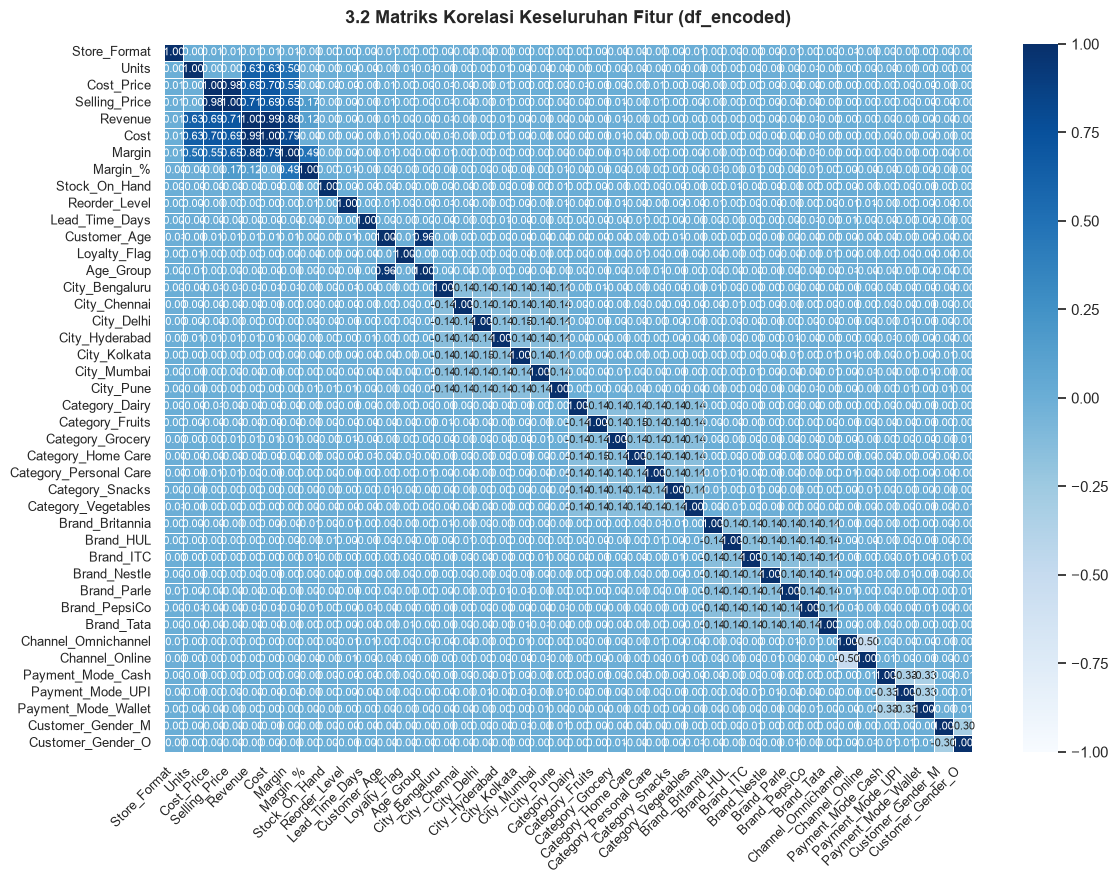

In [35]:
# 1. Hitung korelasi untuk SELURUH kolom yang ada di df_encoded
corr_matrix_full = df_encoded.corr(numeric_only=True)

# 2. Plot Heatmap Keseluruhan
plt.figure(figsize=(12, 9))
sns.set_theme(style="white")

ax = sns.heatmap(
    corr_matrix_full, 
    annot=True, 
    fmt=".2f", 
    cmap='Blues', 
    vmax=1, vmin=-1, center=0,
    linewidths=0.5,
    linecolor='white',
    annot_kws={"size": 8}  # Font diperkecil agar angka di kotak muat rapi
)

plt.title('3.2 Matriks Korelasi Keseluruhan Fitur (df_encoded)', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

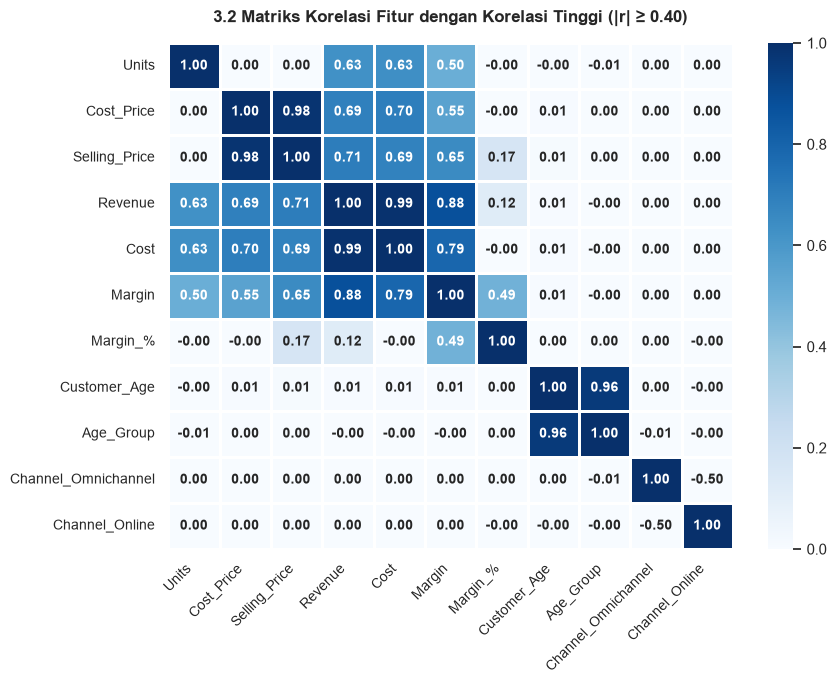

In [35]:
# 1. Hitung matriks korelasi penuh
corr_full = df_encoded.corr(numeric_only=True)

# 2. Filter kolom yang memiliki minimal satu korelasi kuat (selain dengan dirinya sendiri > 0.40)
# Ini membuang kolom ID, City, Store_Format, dll. yang nilainya mendekati 0.00
high_corr_mask = (corr_full.abs() >= 0.40) & (corr_full.abs() < 1.0)
selected_cols = corr_full.columns[high_corr_mask.any()]

df_high_corr = corr_full.loc[selected_cols, selected_cols]

# 3. Plot Heatmap dengan Gradasi Biru (Blues)
plt.figure(figsize=(9, 7))
sns.set_theme(style="white")

ax = sns.heatmap(
    df_high_corr, 
    annot=True, 
    fmt=".2f", 
    cmap='Blues',           
    vmax=1.0, vmin=0.0,
    linewidths=0.8,
    linecolor='white',
    annot_kws={"size": 10, "weight": "bold"}
)

plt.title('3.2 Matriks Korelasi Fitur dengan Korelasi Tinggi (|r| ≥ 0.40)', fontsize=12, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

<b>Hasil Pengamatan</b>
<p>Evaluasi matriks korelasi menunjukkan bahwa kinerja finansial nominal (Revenue dan Margin) digerakkan secara kuat oleh tingginya harga jual (Selling_Price) dan kuantitas barang per transaksi (Units), bukan oleh besaran persentase keuntungan (Margin_%). Di sisi lain, ditemukan redundansi data (multikolinearitas ekstrem) pada profil usia pelanggan (Customer_Age dan Age_Group) dengan korelasi 0,96, serta pada Revenue dan Cost sebesar 0,99.   Oleh karena itu, strategi penjualan disarankan berfokus pada taktik up-selling dan peningkatan ukuran keranjang belanja (basket size) alih-alih hanya mengejar margin persentase tinggi. Selanjutnya, untuk persiapan pemodelan machine learning, tim data disarankan melakukan seleksi fitur dengan menghapus variabel Customer_Age dan Cost guna menghindari bias akibat multikolinearitas.</p>

<h3>F. DATA ANALYSIS</h3>

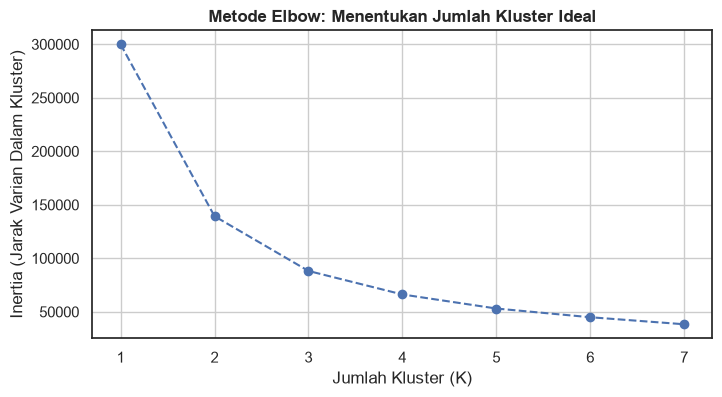

--- 1. PROFIL RATA-RATA TRANSAKSI PER KLUSTER ---
              Revenue  Margin  Units  Jumlah Transaksi
Cluster_Name                                          
Kluster 0      411.59   71.10   3.88             38319
Kluster 1      884.95  206.12   4.38             17828
Kluster 2      177.56   33.63   1.67             43853


--- 2. KOMPOSISI CHANNEL DI MASING-MASING KLUSTER (%) ---
Channel       Offline  Omnichannel  Online
Cluster_Name                              
Kluster 0        33.2         33.7    33.1
Kluster 1        33.0         33.3    33.7
Kluster 2        33.6         33.1    33.2


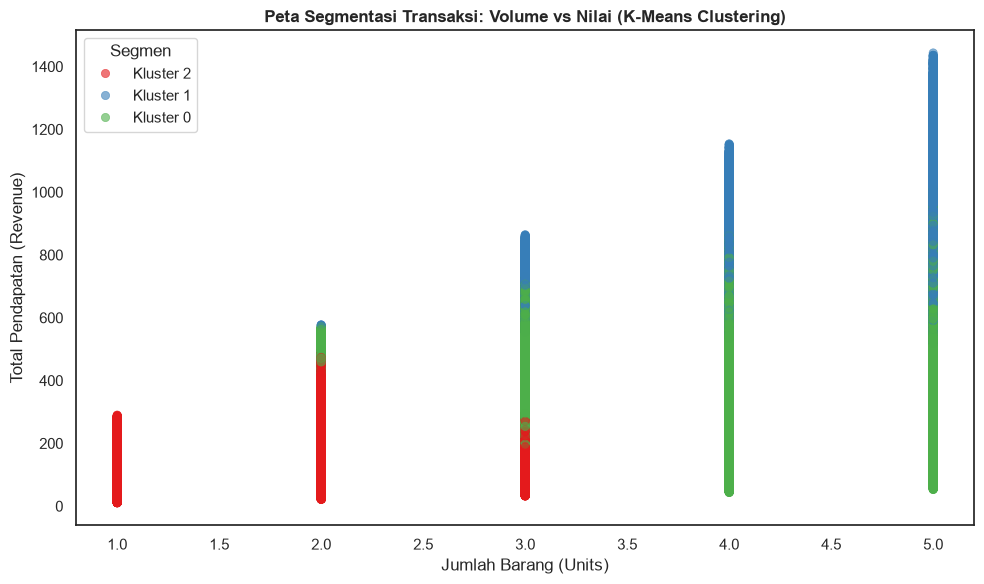

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Asumsi dataset Anda bernama df_clean
# 1. Pemilihan Fitur (Hanya gunakan variabel numerik pendorong nilai)
features = ['Revenue', 'Margin', 'Units']
X = df_clean[features]

# 2. Standarisasi Skala Data (WAJIB)
# Karena Revenue/Margin ribuan dan Units satuan, kita harus menyamakan skalanya 
# agar algoritma tidak bias dan hanya menganggap Revenue yang penting.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================================================================
# TAHAP 1: MENCARI JUMLAH KLUSTER TERBAIK DENGAN ELBOW METHOD
# ==============================================================================
inertia = []
K_range = range(1, 8) # Mencoba membagi dari 1 hingga 7 kelompok

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Metode Elbow: Menentukan Jumlah Kluster Ideal', fontweight='bold')
plt.xlabel('Jumlah Kluster (K)')
plt.ylabel('Inertia (Jarak Varian Dalam Kluster)')
plt.grid(True)
plt.show()

# ==============================================================================
# TAHAP 2: EKSEKUSI K-MEANS & PROFILING (Misal kita asumsikan K=3)
# ==============================================================================
# Catatan: Ubah n_clusters sesuai titik "siku" patahan terdalam dari grafik Elbow di atas
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Mengganti label angka (0,1,2) menjadi nama agar mudah dibaca di presentasi
df_clean['Cluster_Name'] = df_clean['Cluster'].map({
    0: 'Kluster 0', 1: 'Kluster 1', 2: 'Kluster 2'
})

# 3. Evaluasi Karakteristik Bisnis per Kluster
print("--- 1. PROFIL RATA-RATA TRANSAKSI PER KLUSTER ---")
cluster_profile = df_clean.groupby('Cluster_Name')[features].mean().round(2)
cluster_profile['Jumlah Transaksi'] = df_clean.groupby('Cluster_Name').size()
print(cluster_profile)
print("\n")

print("--- 2. KOMPOSISI CHANNEL DI MASING-MASING KLUSTER (%) ---")
# Menyilangkan kluster dengan Channel untuk melihat dari mana pelanggan ini berasal
channel_cross = pd.crosstab(df_clean['Cluster_Name'], df_clean['Channel'], normalize='index') * 100
print(channel_cross.round(1))

# 4. Visualisasi Akhir (Menyajikan Titik Transaksi berdasarkan Volume dan Nilai)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean, 
    x='Units', 
    y='Revenue', 
    hue='Cluster_Name', 
    palette='Set1', 
    alpha=0.6,
    edgecolor=None
)
plt.title('Peta Segmentasi Transaksi: Volume vs Nilai (K-Means Clustering)', fontweight='bold')
plt.xlabel('Jumlah Barang (Units)')
plt.ylabel('Total Pendapatan (Revenue)')
plt.legend(title='Segmen')
plt.tight_layout()
plt.show()

In [50]:
# Asumsi dataframe Anda bernama df_clean
# 1. Agregasi total Margin per Kategori Produk
abc_df = df_clean.groupby('Category')['Margin'].sum().reset_index()

# 2. Urutkan kategori dari perolehan Margin tertinggi ke terendah
abc_df = abc_df.sort_values(by='Margin', ascending=False).reset_index(drop=True)

# 3. Hitung persentase kumulatif kontribusi Margin
total_margin = abc_df['Margin'].sum()
abc_df['Cumulative_Margin'] = abc_df['Margin'].cumsum()
abc_df['Cumulative_Percentage'] = (abc_df['Cumulative_Margin'] / total_margin) * 100

# 4. Klasifikasikan ke dalam Kelas A, B, dan C (Prinsip Pareto: 80-15-5)
def classify_abc(cum_pct):
    if cum_pct <= 80:
        return 'Kelas A (Top ~80% Kontribusi)'
    elif cum_pct <= 95:
        return 'Kelas B (Menengah ~15% Kontribusi)'
    else:
        return 'Kelas C (Bawah ~5% Kontribusi)'

abc_df['ABC_Class'] = abc_df['Cumulative_Percentage'].apply(classify_abc)

# Menampilkan hasil ringkasan tabel ABC Analysis
print("--- TABEL ANALISIS ABC (PARETO) BERDASARKAN MARGIN ---")
print(abc_df.to_string(index=False))

--- TABEL ANALISIS ABC (PARETO) BERDASARKAN MARGIN ---
     Category        Margin  Cumulative_Margin  Cumulative_Percentage                          ABC_Class
      Grocery 996634.794798       9.966348e+05              12.657793      Kelas A (Top ~80% Kontribusi)
       Fruits 993337.256857       1.989972e+06              25.273705      Kelas A (Top ~80% Kontribusi)
       Snacks 992112.232178       2.982084e+06              37.874058      Kelas A (Top ~80% Kontribusi)
   Vegetables 985748.003486       3.967832e+06              50.393583      Kelas A (Top ~80% Kontribusi)
    Beverages 983238.273218       4.951071e+06              62.881232      Kelas A (Top ~80% Kontribusi)
    Home Care 982373.840734       5.933444e+06              75.357903      Kelas A (Top ~80% Kontribusi)
Personal Care 981586.979222       6.915031e+06              87.824580 Kelas B (Menengah ~15% Kontribusi)
        Dairy 958654.274803       7.873686e+06             100.000000     Kelas C (Bawah ~5% Kontribusi)


<h4>1. Analisis Time Series</h4>

<h5>1.1 Smoothing</h5>

In [25]:
daily = df_clean.groupby("Invoice_Date", as_index=False)["Revenue"].sum()
daily = daily.sort_values("Invoice_Date")

daily["SMA_30"] = daily["Revenue"].rolling(window=30).mean()
daily

,Invoice_Date,Revenue,SMA_30
0,2024-01-01 00:00:00,906.681905,NaN
1,2024-01-01 00:01:00,460.352450,NaN
2,2024-01-01 00:06:00,803.368417,NaN
3,2024-01-01 00:09:00,199.359400,NaN
4,2024-01-01 00:10:00,85.149898,NaN
...,...,...,...
91052,2024-12-30 23:47:00,1258.870739,412.733316
91053,2024-12-30 23:48:00,67.019955,391.230224
91054,2024-12-30 23:51:00,180.141795,379.095493
91055,2024-12-30 23:55:00,609.220676,397.616142


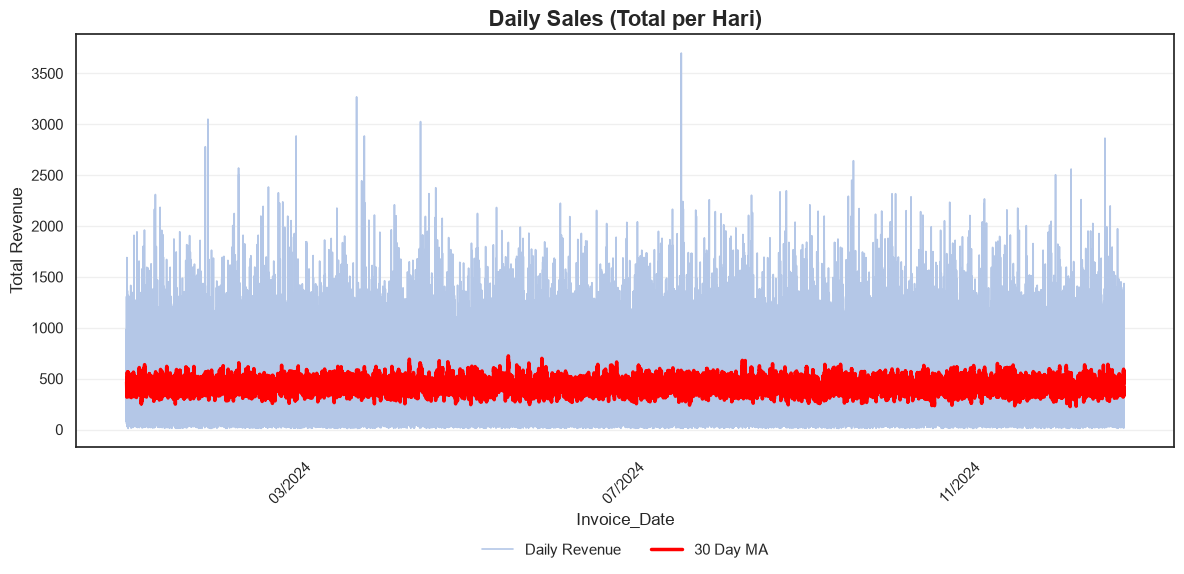

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(daily["Invoice_Date"], daily["Revenue"], color="#B4C7E7", linewidth=1.2, label="Daily Revenue")
plt.plot(daily["Invoice_Date"], daily["SMA_30"], color="red", linewidth=2.5, label="30 Day MA")

plt.title("Daily Sales (Total per Hari)", fontsize=16, fontweight="bold")
plt.xlabel("Invoice_Date")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [37]:
from statsmodels.tsa.stattools import adfuller

In [38]:
ts_sales = (
    df_clean.groupby("Invoice_Date")["Revenue"]
    .sum()
    .sort_index()
)

In [39]:
'''Untuk memastikan data lengkap dan tidak ada yang kosong'''
ts_sales = ts_sales.asfreq("D")                                  
ts_sales = ts_sales.interpolate() 

In [29]:
ts_sales

Invoice_Date
2024-01-01     906.681905
2024-01-02     624.749705
2024-01-03     342.817504
2024-01-04      60.885303
2024-01-05     125.212428
                 ...     
2024-12-26    2863.318386
2024-12-27    2863.318386
2024-12-28    2863.318386
2024-12-29    2863.318386
2024-12-30    2863.318386
Freq: D, Name: Revenue, Length: 365, dtype: float64

In [40]:
result = adfuller(ts_sales.dropna())
print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] < 0.05:
    print("Tolak H0: terdapat bukti bahwa series stasioner")
else:
    print("Gagal menolak H0: series belum terbukti stasioner")

ADF Statistic: -2.9181032446941053
P-value: 0.04328297379293859
Tolak H0: terdapat bukti bahwa series stasioner


<Figure size 1500x500 with 0 Axes>

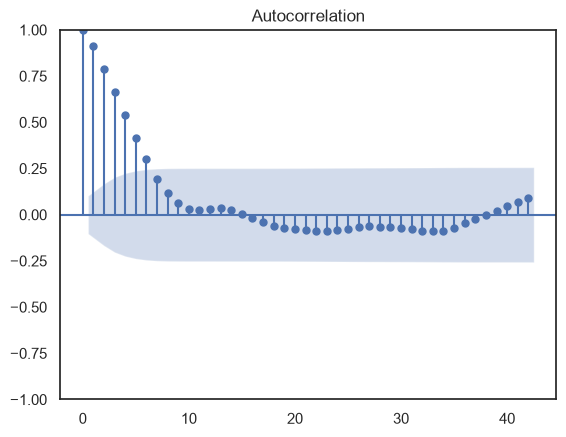

In [41]:
plt.figure(figsize=(15,5))

plot_acf(ts_sales, lags=42)

plt.show()

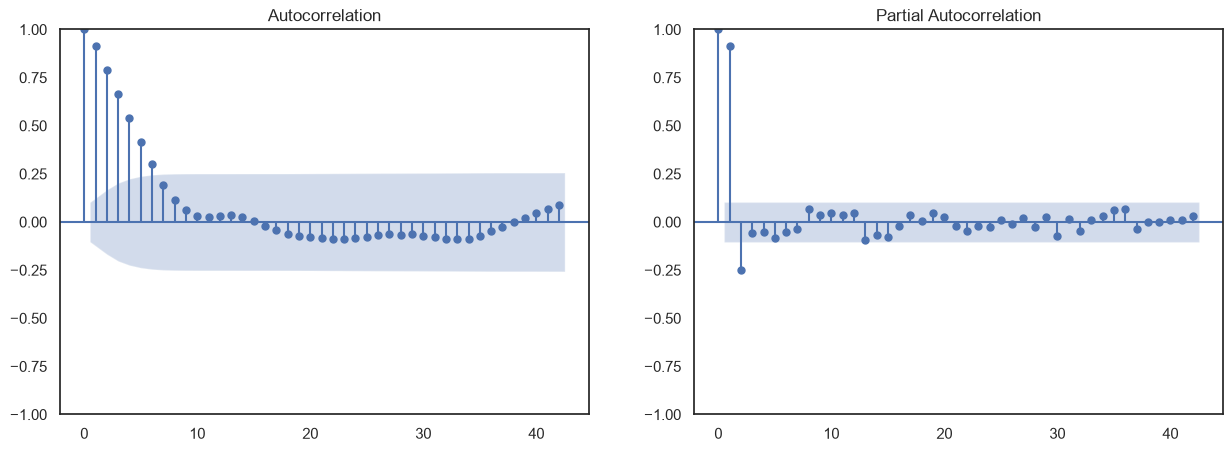

In [42]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plot_acf(ts_sales, lags=42, ax=plt.gca())

plt.subplot(1,2,2)
plot_pacf(ts_sales, lags=42, ax=plt.gca())

plt.show()

                          model  d       AIC       BIC  RMSE_test  MAPE_%  LjungBox_p  konvergen
0  SARIMA(3, 0, 0)x(0, 1, 1, 7)  0 -4349.841 -4331.492      0.001  82.499       0.004      False
1  SARIMA(2, 0, 0)x(0, 1, 1, 7)  0 -4352.839 -4338.159      0.001  82.486       0.006      False
2  SARIMA(1, 0, 1)x(0, 1, 1, 7)  0 -4333.133 -4318.467      0.001  82.564       0.001      False
3  SARIMA(1, 0, 0)x(0, 1, 1, 7)  0 -4314.697 -4303.688      0.001  82.405       0.000       True
4  SARIMA(1, 0, 0)x(1, 1, 1, 7)  0 -4302.949 -4288.270      0.001  80.892       0.000      False
5  SARIMA(1, 0, 1)x(1, 1, 1, 7)  0 -4318.767 -4300.435      0.001  77.800       0.000      False
6  SARIMA(0, 1, 1)x(0, 1, 1, 7)  1 -4344.382 -4333.393      0.001  70.470       0.482       True


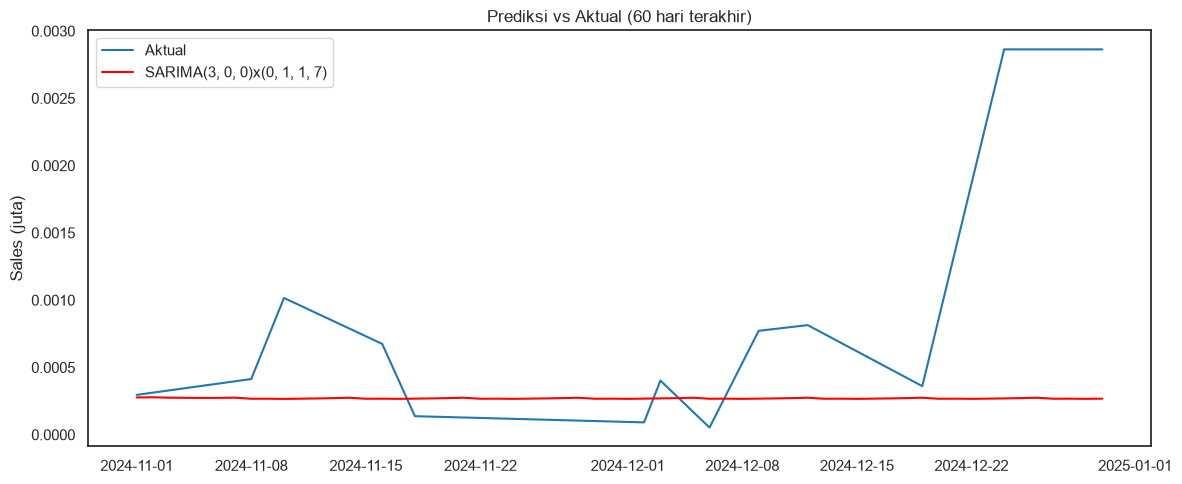

In [31]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

ts = ts_sales / 1e6            # ts_sales = versi asfreq("D") + interpolate, ASLI (bukan hasil diff)
horizon = 60
train, test = ts.iloc[:-horizon], ts.iloc[-horizon:]

kandidat = [
    # jalur baru: d=0, D=1 (dari ACF/PACF diff(7))
    ((1,0,0), (0,1,1,7)),
    ((1,0,1), (0,1,1,7)),
    ((2,0,0), (0,1,1,7)),
    ((3,0,0), (0,1,1,7)),
    ((1,0,0), (1,1,1,7)),
    ((1,0,1), (1,1,1,7)),
    ((0,1,1), (0,1,1,7)),
]

rows, prediksi = [], {}
for order, seas in kandidat:
    try:
        m = SARIMAX(train, order=order, seasonal_order=seas,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        fc = m.get_forecast(horizon).predicted_mean
        rmse = np.sqrt(np.mean((test.values - fc.values) ** 2))
        mape = np.mean(np.abs((test.values - fc.values) / test.values)) * 100
        lb_p = acorr_ljungbox(m.resid.iloc[8:], lags=[14], return_df=True)["lb_pvalue"].iloc[0]
        nama = f"SARIMA{order}x{seas}"
        rows.append({"model": nama, "d": order[1], "AIC": m.aic, "BIC": m.bic,
                     "RMSE_test": rmse, "MAPE_%": mape, "LjungBox_p": lb_p,
                     "konvergen": m.mle_retvals.get("converged", None)})
        prediksi[nama] = fc
    except Exception as e:
        print("Gagal:", order, seas, "->", e)

tabel = pd.DataFrame(rows).sort_values("RMSE_test").reset_index(drop=True)
print(tabel.round(3).to_string())

terbaik = tabel.loc[0, "model"]
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Aktual", color="#1f77b4")
plt.plot(test.index, prediksi[terbaik], label=terbaik, color="red")
plt.title("Prediksi vs Aktual (60 hari terakhir)")
plt.ylabel("Sales (juta)"); plt.legend(); plt.tight_layout(); plt.show()

In [32]:
from pmdarima import auto_arima

# auto_arima akan mendeteksi differencing dan parameter musiman secara otomatis
stepwise_model = auto_arima(ts_sales, 
                            seasonal=True, 
                            m=7,            # Sesuaikan siklus musim (misal 7 untuk harian)
                            trace=True,
                            error_action='ignore',
                            suppress_warnings=True,
                            stepwise=True)

print(stepwise_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[7] intercept   : AIC=4563.633, Time=1.94 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=5483.052, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[7] intercept   : AIC=4621.429, Time=0.87 sec
 ARIMA(0,0,1)(0,0,1)[7] intercept   : AIC=5084.730, Time=0.92 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=5773.123, Time=0.03 sec
 ARIMA(2,0,2)(0,0,1)[7] intercept   : AIC=4563.986, Time=2.19 sec
 ARIMA(2,0,2)(1,0,0)[7] intercept   : AIC=4563.935, Time=1.12 sec
 ARIMA(2,0,2)(2,0,1)[7] intercept   : AIC=4562.864, Time=3.53 sec
 ARIMA(2,0,2)(2,0,0)[7] intercept   : AIC=4560.708, Time=2.46 sec
 ARIMA(1,0,2)(2,0,0)[7] intercept   : AIC=4559.315, Time=1.76 sec
 ARIMA(1,0,2)(1,0,0)[7] intercept   : AIC=4562.304, Time=1.41 sec
 ARIMA(1,0,2)(2,0,1)[7] intercept   : AIC=4561.468, Time=2.67 sec
 ARIMA(1,0,2)(1,0,1)[7] intercept   : AIC=4564.798, Time=1.14 sec
 ARIMA(0,0,2)(2,0,0)[7] intercept   : AIC=4840.195, Time=1.90 sec
 ARIMA(1,0,1)(2,0,0)[7] intercept

In [ ]:
!pip install pmdarima

In [33]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from pmdarima import auto_arima

# Mempersiapkan data (skala juta)
ts = ts_sales / 1e6                    # ts_sales = versi asfreq("D") + interpolate
horizon = 60
train, test = ts.iloc[:-horizon], ts.iloc[-horizon:]

def evaluasi(nama, order, seas):
    m = SARIMAX(train, order=order, seasonal_order=seas,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
    fc = m.get_forecast(horizon).predicted_mean
    rmse = np.sqrt(np.mean((test.values - fc.values) ** 2))
    mape = np.mean(np.abs((test.values - fc.values) / test.values)) * 100
    lb_p = acorr_ljungbox(m.resid.iloc[8:], lags=[14], return_df=True)["lb_pvalue"].iloc[0]
    return {"model": nama, "AIC": m.aic, "RMSE_test": rmse, "MAPE_%": mape, "LjungBox_p": lb_p}

hasil = []

# 1. Model manual berdasarkan pembacaan awal
hasil.append(evaluasi("Manual: (1,0,1)x(1,1,1,7)", (1,0,1), (1,1,1,7)))

# 2. Model hasil rekomendasi auto_arima baru dari gambar (SARIMAX 2,0,0 x 2,0,0,7)
hasil.append(evaluasi("Auto: (2,0,0)x(2,0,0,7)", (2,0,0), (2,0,0,7)))

# 3. auto_arima otomatis via script Python
auto = auto_arima(train, seasonal=True, m=7, d=0, D=0,
                  start_p=0, max_p=3, start_q=0, max_q=3,
                  start_P=0, max_P=2, start_Q=0, max_Q=2,
                  stepwise=True, trace=True, error_action="ignore", suppress_warnings=True)

print("auto_arima terpilih:", auto.order, auto.seasonal_order)
hasil.append(evaluasi(f"auto_arima auto: {auto.order}x{auto.seasonal_order}", auto.order, auto.seasonal_order))

# Menampilkan tabel perbandingan diurutkan berdasarkan RMSE terkecil
df_hasil = pd.DataFrame(hasil).sort_values("RMSE_test").round(3)
print(df_hasil.to_string(index=False))

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=-4181.447, Time=0.17 sec
 ARIMA(1,0,0)(1,0,0)[7] intercept   : AIC=-4460.971, Time=2.03 sec
 ARIMA(0,0,1)(0,0,1)[7] intercept   : AIC=-4349.572, Time=1.28 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=-3770.845, Time=0.15 sec
 ARIMA(1,0,0)(0,0,0)[7] intercept   : AIC=-4630.471, Time=0.22 sec
 ARIMA(1,0,0)(0,0,1)[7] intercept   : AIC=-4464.115, Time=1.11 sec
 ARIMA(1,0,0)(1,0,1)[7] intercept   : AIC=-4520.262, Time=1.11 sec
 ARIMA(2,0,0)(0,0,0)[7] intercept   : AIC=-4669.028, Time=0.34 sec
 ARIMA(2,0,0)(1,0,0)[7] intercept   : AIC=-4519.099, Time=1.69 sec
 ARIMA(2,0,0)(0,0,1)[7] intercept   : AIC=-4522.466, Time=1.46 sec
 ARIMA(2,0,0)(1,0,1)[7] intercept   : AIC=-4573.792, Time=1.52 sec
 ARIMA(3,0,0)(0,0,0)[7] intercept   : AIC=-4667.537, Time=0.35 sec
 ARIMA(2,0,1)(0,0,0)[7] intercept   : AIC=-4666.826, Time=0.37 sec
 ARIMA(1,0,1)(0,0,0)[7] intercept   : AIC=-4665.214, Time=0.24 sec
 ARIMA(3,0,1)(0,0,0

365 <Day>
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3837      0.005    278.367      0.000       1.374       1.393
ar.L2         -0.3983      0.004    -93.909      0.000      -0.407      -0.390
sigma2       1.53e-08   4.85e-10     31.546      0.000    1.43e-08    1.62e-08
            prediksi  batas_bawah  batas_atas       hari
2024-12-31     0.003        0.003       0.003    Tuesday
2025-01-01     0.003        0.002       0.003  Wednesday
2025-01-02     0.003        0.002       0.003   Thursday
2025-01-03     0.003        0.002       0.003     Friday
2025-01-04     0.003        0.002       0.003   Saturday
2025-01-05     0.003        0.002       0.003     Sunday
2025-01-06     0.002        0.002       0.003     Monday
2025-01-07     0.002        0.001       0.003    Tuesday
2025-01-08     0.002        0.001       0.003  Wednesday
2025-01-09     0.002     

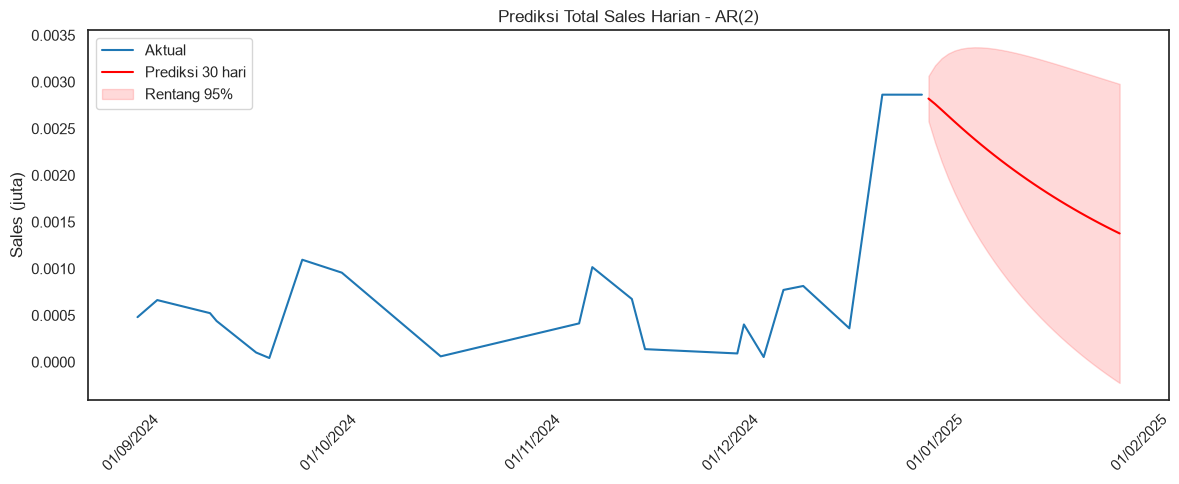


Total prediksi 30 hari   : 0.06 juta
Rata-rata hari kerja    : 0.002 juta
Rata-rata akhir pekan   : 0.002 juta
Hari tertinggi          : 2024-12-31 (0.003 juta)
Hari terendah           : 2025-01-29 (0.001 juta)


In [62]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX

ts = ts_sales / 1e6                     # ts_sales = versi asfreq("D") + interpolate
print(len(ts), ts.index.freq)           # harus: 1688 <Day>

# 1. Fit ulang dengan SELURUH data menggunakan parameter terbaik dari auto_arima
model_final = SARIMAX(ts, order=(2,0,0), seasonal_order=(0,0,0,7),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
print(model_final.summary().tables[1])  # koefisien model

# 2. Prediksi 30 hari
n_hari = 30
hasil = model_final.get_forecast(n_hari).summary_frame(alpha=0.05)[["mean", "mean_ci_lower", "mean_ci_upper"]]
hasil.columns = ["prediksi", "batas_bawah", "batas_atas"]
hasil.index = pd.date_range(start=ts.index[-1] + pd.Timedelta(days=1), periods=n_hari, freq="D")
hasil["hari"] = hasil.index.day_name()
print(hasil.round(3).to_string())

# 3. Grafik
plt.figure(figsize=(12, 5))
plt.plot(ts.index[-120:], ts.iloc[-120:], label="Aktual", color="#1f77b4")
plt.plot(hasil.index, hasil["prediksi"], label="Prediksi 30 hari", color="red")
plt.fill_between(hasil.index, hasil["batas_bawah"], hasil["batas_atas"], color="red", alpha=0.15, label="Rentang 95%")
plt.title("Prediksi Total Sales Harian - AR(2)")
plt.ylabel("Sales (juta)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# 4. Angka ringkas
akhir_pekan = hasil["hari"].isin(["Saturday", "Sunday"])
print(f"\nTotal prediksi 30 hari   : {hasil['prediksi'].sum():.2f} juta")
print(f"Rata-rata hari kerja    : {hasil.loc[~akhir_pekan, 'prediksi'].mean():.3f} juta")
print(f"Rata-rata akhir pekan   : {hasil.loc[akhir_pekan, 'prediksi'].mean():.3f} juta")
print(f"Hari tertinggi          : {hasil['prediksi'].idxmax().date()} ({hasil['prediksi'].max():.3f} juta)")
print(f"Hari terendah           : {hasil['prediksi'].idxmin().date()} ({hasil['prediksi'].min():.3f} juta)")

In [31]:
df_clean.describe()

,Invoice_Date,Units,Cost_Price,Selling_Price,Revenue,Cost,Margin,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Dead_Capital_Value,Stockout_Risk_Ratio
count,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,59919.0,100000.000000,100000.000000
mean,2024-07-01 10:48:28.414800,2.998290,104.859625,131.107353,393.351350,314.614493,78.736857,0.193368,274.156670,49.467710,8.516810,41.07662,86164.683524,6.421993
min,2024-01-01 00:00:00,1.000000,10.000526,10.580915,10.653198,10.002024,0.556870,0.047621,50.000000,20.000000,3.000000,18.0,515.356357,0.632911
25%,2024-04-01 04:27:30,2.000000,57.478508,71.327813,155.415176,125.467072,24.448402,0.131251,161.000000,34.000000,6.000000,29.0,26235.131471,3.274194
50%,2024-07-01 18:21:30,3.000000,104.903700,129.999158,313.349100,252.801900,53.552720,0.200287,274.000000,50.000000,9.000000,41.0,58430.324746,5.541667
75%,2024-09-30 13:00:15,4.000000,152.320122,188.854907,573.063568,462.376451,110.075103,0.259151,387.000000,64.000000,12.000000,53.0,120393.835604,8.345455
max,2024-12-30 23:57:00,5.000000,199.999659,289.699598,1443.134985,999.985219,447.207497,0.310343,499.000000,79.000000,14.000000,64.0,495152.396305,24.950000
std,NaN,1.414619,54.825341,69.862379,297.154653,234.901995,74.236348,0.075143,129.853861,17.305614,3.458274,13.565069,81993.877262,4.251116


In [32]:
df_clean['Margin']

0         52.116348
1         25.407438
2        138.734266
3        130.137115
4         21.157751
            ...    
99995    226.955069
99996    229.419198
99997     22.679513
99998     69.208946
99999      8.666590
Name: Margin, Length: 100000, dtype: float64

In [55]:

# 3. Export dataset bersih ke CSV (tanpa menyertakan index)
df_clean.to_csv('finpro_cleaned.csv', index=False)
print("Berhasil! Data siap diload ke Power BI.")

Berhasil! Data siap diload ke Power BI.


In [34]:
# Tentukan kolom-kolom desimal yang ingin dicek
kolom_desimal = ['Cost_Price', 'Selling_Price', 'Revenue', 'Cost', 'Margin', 'Margin_%']

# Cek jumlah nilai unik setelah dibulatkan ke 2 desimal (hanya view, tidak permanen)
print(df[kolom_desimal].round(2).nunique())

Cost_Price       18914
Selling_Price    25551
Revenue          60316
Cost             54335
Margin           24476
Margin_%            27
dtype: int64


In [54]:
display(df_clean)

,Transaction_ID,Invoice_ID,Invoice_Date,City,Store_Format,Category,Brand,Channel,Payment_Mode,Units,...,Margin_%,Stock_On_Hand,Reorder_Level,Lead_Time_Days,Customer_Age,Customer_Gender,Loyalty_Flag,Age_Group,Margin_Leakage_Flag,Basket_Size_Segment
0,TRX-1,58018430,2024-02-02 13:50:00,Kolkata,Super,Grocery,Nestle,Online,Wallet,2,...,0.148855,154,31,11,20,M,True,18-25,Underperforming,Small Basket
1,TRX-2,48157952,2024-10-09 11:52:00,Hyderabad,Hyper,Home Care,PepsiCo,Offline,Wallet,1,...,0.239616,130,24,5,26,F,True,26-35,Overperforming,Small Basket
2,TRX-3,23283831,2024-08-26 22:03:00,Chennai,Hyper,Snacks,PepsiCo,Online,Card,5,...,0.132773,270,44,8,27,F,False,26-35,Underperforming,Large/Max Basket
3,TRX-4,53537460,2024-06-09 04:34:00,Bengaluru,Hyper,Beverages,Nestle,Omnichannel,Card,2,...,0.249420,403,63,8,<NA>,F,False,Unknown,Overperforming,Small Basket
4,TRX-5,55348596,2024-06-07 01:13:00,Delhi,Super,Snacks,ITC,Offline,Card,3,...,0.230292,366,40,9,60,F,True,51+,Overperforming,Medium Basket
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,TRX-99996,51439182,2024-08-11 14:58:00,Mumbai,Express,Dairy,Britannia,Online,Cash,5,...,0.261277,70,76,6,25,O,False,18-25,Overperforming,Large/Max Basket
99996,TRX-99997,76433622,2024-11-27 11:02:00,Ahmedabad,Express,Dairy,Amul,Offline,Wallet,4,...,0.238526,482,31,14,25,M,True,18-25,Overperforming,Medium Basket
99997,TRX-99998,80228351,2024-02-21 09:25:00,Bengaluru,Express,Beverages,ITC,Omnichannel,Wallet,2,...,0.064810,411,40,4,<NA>,F,False,Unknown,Underperforming,Small Basket
99998,TRX-99999,49574701,2024-03-30 04:11:00,Chennai,Hyper,Dairy,PepsiCo,Offline,UPI,4,...,0.256204,488,46,12,21,M,True,18-25,Overperforming,Medium Basket


In [52]:
# Menimpa kembali df_clean dengan hasil drop
df_clean = df_clean.drop(columns=['Dead_Capital_Value', 'Stockout_Risk_Ratio'], errors='ignore')

In [53]:
# Memastikan kolom berhasil dihapus
print(df_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Transaction_ID       100000 non-null  str           
 1   Invoice_ID           100000 non-null  str           
 2   Invoice_Date         100000 non-null  datetime64[us]
 3   City                 100000 non-null  category      
 4   Store_Format         100000 non-null  category      
 5   Category             100000 non-null  category      
 6   Brand                100000 non-null  category      
 7   Channel              100000 non-null  category      
 8   Payment_Mode         100000 non-null  category      
 9   Units                100000 non-null  int64         
 10  Cost_Price           100000 non-null  float64       
 11  Selling_Price        100000 non-null  float64       
 12  Revenue              100000 non-null  float64       
 13  Cost                 10000